# Modelos avançados — rodada de melhorias

Segunda rodada dos modelos avançados, **a partir do que a primeira rodada
(`05_modelos_avancados_kaggle.ipynb`) mostrou**:

- A avaliação em 5 partições deu STab (KS 0.535 ± 0.013) e TabKAN
  (0.531 ± 0.018) à frente de XGB/MLP/GB — são os candidatos com mais
  margem para melhorar.
- Em uma única partição o KS tem erro-padrão ≈ 0.02, então qualquer ganho
  aqui só conta se aparecer também na **avaliação robusta** (seção final).
- TabPFN e Mitra só foram bem com contexto **sem duplicatas** + correção de
  prior — as variantes novas partem dessa configuração.

**Auditoria:** nada da rodada anterior é reexecutado ou sobrescrito. Cada
experimento grava um `model_id` novo e descritivo (o nome diz o modelo e o
que mudou); `checar_id_novo` aborta se o ID já existir em `results/` do
repositório, e o push nunca substitui arquivo já versionado. Todas as
melhorias são **opções novas** nos wrappers de `src/churn_telecom/models/`,
com padrões que reproduzem exatamente a rodada anterior.

**No Kaggle, antes de rodar:** *Settings → Internet → On* e
*Accelerator → GPU*; depois **"Save Version" → "Save & Run All (Commit)"**.


In [1]:
#@title Setup (clona o repo e instala o pacote)
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/jpbezerra/redes-neurais.git"   # ajuste se necessario
BRANCH   = "feat/churn"   # ajuste aqui se a branch de trabalho mudar
REPO_DIR = "redes-neurais"
SUBPATH  = "projeto/churn-telecom"

def _sh(cmd):
    print("$", cmd); subprocess.run(cmd, shell=True, check=False)

IN_COLAB  = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle")

if IN_COLAB or IN_KAGGLE:
    base = Path("/content") if IN_COLAB else Path("/kaggle/temp")  # fora de /kaggle/working: o clone nao entra no Output
    root = base / REPO_DIR
    if root.exists():
        _sh(f"cd {root} && git fetch origin {BRANCH} && git checkout {BRANCH} && git pull --ff-only origin {BRANCH}")
    else:
        _sh(f"git clone --branch {BRANCH} --single-branch {REPO_URL} {root}")
    PROJECT_ROOT = root / SUBPATH
    _sh(f"pip install -q -e {PROJECT_ROOT}")
else:
    PROJECT_ROOT = Path.cwd().parent

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# No Kaggle, tudo que for gerado vai para /kaggle/working/saida (so isso aparece
# no Output, em vez do repositorio inteiro).
OUT_DIR = Path("/kaggle/working/saida") if IN_KAGGLE else PROJECT_ROOT

DATA_DIR    = PROJECT_ROOT / "data"
RESULTS_DIR = OUT_DIR / "results"
TABLES_DIR  = OUT_DIR / "reports" / "tables"
for d in (DATA_DIR, RESULTS_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULTS_DIR :", RESULTS_DIR)


$ git clone --branch feat/churn --single-branch https://github.com/jpbezerra/redes-neurais.git /kaggle/temp/redes-neurais


Cloning into '/kaggle/temp/redes-neurais'...
Updating files: 100% (1838/1838), done.


$ pip install -q -e /kaggle/temp/redes-neurais/projeto/churn-telecom
PROJECT_ROOT: /kaggle/temp/redes-neurais/projeto/churn-telecom
RESULTS_DIR : /kaggle/working/saida/results


## Instalação dos modelos avançados

In [2]:
!pip install -q tabpfn pykan tabkan
# AutoGluon so e usado pelo Mitra (rodada 2, ja versionada): instalar so se a rodada 2 for rodar
if not (PROJECT_ROOT / "reports" / "tables" / "avaliacao_robusta_modelos_melhorados_resumo.csv").exists():
    !pip install -q "autogluon.tabular[mitra]"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 28.8 MB/s eta 0:00:00


## Preparação dos dados

Mesma partição da rodada anterior (`SEED = 0`), então as probabilidades
já salvas (`predicoes.npz`) dos modelos antigos se alinham linha a linha com
as dos novos — dá para combiná-los em ensemble sem retreinar nada.


In [3]:
import torch
import joblib
import numpy as np
import pandas as pd

from churn_telecom.data import load_raw, split_three_stage, assert_sem_vazamento
from churn_telecom.features import Preprocessor
from churn_telecom.metrics import full_report
from churn_telecom.checkpointing import save_run, load_all_metadata
from churn_telecom.ensemble import corrigir_prior, salvar_predicoes, media_probabilidades

SEED = 0
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

df = load_raw(DATA_DIR)
split = split_three_stage(df, seed=SEED)
assert_sem_vazamento(split)
df_train, df_val, df_test = df.iloc[split.train_idx], df.iloc[split.val_idx], df.iloc[split.test_idx]

prep = Preprocessor().fit(df_train)
X_train, cols = prep.transform(df_train)
X_val, _ = prep.transform(df_val)
X_test, _ = prep.transform(df_test)
y_train = prep.transform_target(df_train)
y_val = prep.transform_target(df_val)
y_test = prep.transform_target(df_test)

# Versao SEM linhas duplicadas do treino (mesmas linhas originais, sem oversampling).
# TabPFN/Mitra fazem in-context learning: linhas repetidas viram memorizacao e
# distorcem a calibracao, entao eles tambem sao treinados nesta versao.
df_train_nat = df.iloc[split.train_no_oversample_idx]
X_train_nat, _ = prep.transform(df_train_nat)
y_train_nat = prep.transform_target(df_train_nat)
PRIOR_NAT = float(y_train_nat.mean())

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")
print(f"X_train_nat (sem duplicatas): {X_train_nat.shape} | prior de churn: {PRIOR_NAT:.3f}")


device: cuda
Baixando CSV de https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv ...
CSV salvo em /kaggle/temp/redes-neurais/projeto/churn-telecom/data/telco_customer_churn.csv
X_train: (5174, 40) | X_val: (2588, 40) | X_test: (1761, 40)
X_train_nat (sem duplicatas): (3521, 40) | prior de churn: 0.265


## Utilitários

Igual à rodada anterior (`rodar` isola falhas por modelo), mais:

- `checar_id_novo`: aborta o experimento se o `model_id` já existir no
  Output **ou** em `results/` do repositório clonado (nunca sobrescreve
  a auditoria);
- `salvar`: grava também KS/AUROC de **validação** no `metadata.json`, para
  que a escolha entre variantes (feita só na validação) fique registrada.


In [4]:
import traceback

from churn_telecom.metrics import auroc
from churn_telecom.ensemble import media_logits

FALHAS = {}
RESULTS_REPO = PROJECT_ROOT / "results"   # resultados ja versionados (rodadas anteriores)

def checar_id_novo(model_id):
    for base in (RESULTS_DIR, RESULTS_REPO):
        if (base / model_id).exists():
            raise FileExistsError(f"{model_id} ja existe em {base} — use um ID novo (auditoria).")

def metricas_validacao(p_val):
    return {"ks_validacao": full_report(y_val, p_val)["ks"], "auroc_validacao": auroc(y_val, p_val)}

def salvar(model_id, prever, corrigir=None, **kwargs):
    # prever(X) -> probabilidades; corrigir ajusta o prior (TabPFN/Mitra sem duplicatas)
    pv, pt = prever(X_val), prever(X_test)
    if corrigir is not None:
        pv, pt = corrigir(pv), corrigir(pt)
    metricas = full_report(y_test, pt)
    val = metricas_validacao(pv)
    print(model_id, "| val:", {k: round(v, 4) for k, v in val.items()},
          "| teste:", {k: round(metricas[k], 4) for k in ("ks", "auroc", "recall", "precision")})
    save_run(RESULTS_DIR, model_id, metrics=metricas, dataset_info={"metricas_validacao": val}, **kwargs)
    salvar_predicoes(RESULTS_DIR, model_id, pv, pt)
    return val

# Etapas da rodada 2 (melhorias manuais) — ja executadas e versionadas em results/.
# Num novo "Run All" elas sao puladas; so as etapas novas rodam.
ETAPAS_RODADA_2 = {
    "stab_churn_dim32_depth2_heads4_embfeature_parada_auroc_plateau",
    "stab_churn_dim64_depth3_heads8_embfeature_parada_auroc_plateau", "stab_bagging",
    "tabkan_churn_chebyshev_largura10_grau3_parada_auroc_plateau",
    "tabkan_churn_chebyshev_largura32_grau3_wd1e-4_parada_auroc_plateau",
    "kan", "tabpfn", "mitra", "xgb", "ensembles", "avaliacao_robusta",
}
RODADA_2_CONCLUIDA = (PROJECT_ROOT / "reports" / "tables" / "avaliacao_robusta_modelos_melhorados_resumo.csv").exists()

# Idem para a rodada 3 (busca Optuna).
ETAPAS_RODADA_3 = {f"optuna_{a}" for a in ("mlp", "gb", "xgb", "stab", "tabkan", "kan")} | {
    "grafico_importancias", "avaliacao_robusta_optuna"}
RODADA_3_CONCLUIDA = (PROJECT_ROOT / "reports" / "tables" / "avaliacao_robusta_optuna_resumo.csv").exists()

def rodar(nome, fn):
    if RODADA_2_CONCLUIDA and nome in ETAPAS_RODADA_2:
        print(f"[pulado] {nome} (rodada 2 ja executada e versionada)")
        return
    if RODADA_3_CONCLUIDA and nome in ETAPAS_RODADA_3:
        print(f"[pulado] {nome} (rodada 3 ja executada e versionada)")
        return
    try:
        fn()
        print(f"[ok] {nome}")
    except Exception as e:
        FALHAS[nome] = f"{type(e).__name__}: {e}"
        print(f"[FALHOU] {nome}: {type(e).__name__}: {e}")
        traceback.print_exc()

VALIDACAO = {}   # model_id -> metricas de validacao (para escolher variantes sem olhar o teste)


## STab — melhorias de treino e de embedding

Rodada anterior: `stab_churn_dim32_depth2_heads4_oversample` (embedding
compartilhado + posicional, parada pela cross-entropy de validação).

Mudanças testadas (opções novas em `models/stab.py`):

- **embedding por feature** (`W_i·x + b_i`, como no FT-Transformer): cada
  feature ganha sua própria projeção, em vez de uma projeção única
  diferenciada só por um vetor posicional somado;
- **parada e escolha da época pelo AUROC de validação** — o KS só depende
  da ordem dos scores, então o critério de ranking é mais alinhado do que
  a cross-entropy (que também premia calibração);
- **ReduceLROnPlateau** + gradient clipping + `weight_decay` maior.

Duas capacidades: a mesma do original e uma maior. A melhor (pelo AUROC de
**validação**) é depois re-treinada com 5 sementes e as probabilidades são
médias (*bagging de sementes*) — redes pequenas em dados tabulares variam
bastante entre sementes, e a média reduz essa variância.


In [5]:
from churn_telecom.models.stab import STabHyperparams, treinar_stab, prever_stab

MELHORIAS_TREINO = dict(embedding="por_feature", early_stop_metric="val_auroc",
                        scheduler="plateau", max_grad_norm=1.0, patience=20)

CONFIGS_STAB = {
    "stab_churn_dim32_depth2_heads4_embfeature_parada_auroc_plateau":
        STabHyperparams(dim=32, depth=2, heads=4, attn_dropout=0.1, ff_dropout=0.1, lr=1e-3,
                        weight_decay=1e-4, batch_size=64, max_epochs=200, seed=SEED, **MELHORIAS_TREINO),
    "stab_churn_dim64_depth3_heads8_embfeature_parada_auroc_plateau":
        STabHyperparams(dim=64, depth=3, heads=8, attn_dropout=0.15, ff_dropout=0.15, lr=5e-4,
                        weight_decay=1e-4, batch_size=128, max_epochs=200, seed=SEED, **MELHORIAS_TREINO),
}

def experimento_stab(model_id, hp):
    checar_id_novo(model_id)
    modelo, historico = treinar_stab(X_train, y_train, X_val, y_val, hp, device=device, verbose=True)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_stab(modelo, X, device=device),
        framework="PyTorch (STab — implementacao propria)", hyperparameters=hp.__dict__,
        architecture={"dim": hp.dim, "depth": hp.depth, "heads": hp.heads, "embedding": hp.embedding},
        history=historico, notes="STab com embedding por feature, parada pelo AUROC de validacao e ReduceLROnPlateau.",
        save_model_fn=lambda d: torch.save(modelo.state_dict(), d / "model.pt"))

for mid, hp in CONFIGS_STAB.items():
    rodar(mid, lambda mid=mid, hp=hp: experimento_stab(mid, hp))


[pulado] stab_churn_dim32_depth2_heads4_embfeature_parada_auroc_plateau (rodada 2 ja executada e versionada)
[pulado] stab_churn_dim64_depth3_heads8_embfeature_parada_auroc_plateau (rodada 2 ja executada e versionada)


In [6]:
from dataclasses import replace

N_SEMENTES_BAGGING = 5

def melhor_por_validacao(ids):
    candidatos = [i for i in ids if i in VALIDACAO]
    if not candidatos:
        raise RuntimeError(f"nenhuma variante concluiu: {ids}")
    return max(candidatos, key=lambda i: VALIDACAO[i]["auroc_validacao"])

def experimento_stab_bagging():
    base_id = melhor_por_validacao(CONFIGS_STAB)
    model_id = f"{base_id}_bagging{N_SEMENTES_BAGGING}sementes"
    checar_id_novo(model_id)
    print("config escolhida pela validacao:", base_id)
    modelos = []
    for k in range(N_SEMENTES_BAGGING):
        hp = replace(CONFIGS_STAB[base_id], seed=SEED + k)
        m, _ = treinar_stab(X_train, y_train, X_val, y_val, hp, device=device)
        modelos.append(m)
    prever = lambda X: np.mean([prever_stab(m, X, device=device) for m in modelos], axis=0)
    def salvar_pesos(d):
        for k, m in enumerate(modelos):
            torch.save(m.state_dict(), d / f"model_seed{SEED + k}.pt")
    VALIDACAO[model_id] = salvar(
        model_id, prever, framework="PyTorch (STab — implementacao propria)",
        hyperparameters={**CONFIGS_STAB[base_id].__dict__, "seeds": [SEED + k for k in range(N_SEMENTES_BAGGING)]},
        architecture={"config_base": base_id}, save_model_fn=salvar_pesos,
        notes=f"Media das probabilidades de {N_SEMENTES_BAGGING} sementes da config {base_id} (escolhida pelo AUROC de validacao).")

rodar("stab_bagging", experimento_stab_bagging)


[pulado] stab_bagging (rodada 2 ja executada e versionada)


## TabKAN — mesmas melhorias de treino, mais largura

Rodada anterior: `tabkan_churn_chebyshev_largura10_grau3_oversample`.
Aqui: parada pelo AUROC de validação + ReduceLROnPlateau + clipping, na
mesma largura e numa camada oculta mais larga com `weight_decay` maior.


In [7]:
from churn_telecom.models.tabkan import TabKANHyperparams, treinar_tabkan, prever_tabkan

MELHORIAS_TABKAN = dict(early_stop_metric="val_auroc", scheduler="plateau", max_grad_norm=1.0, patience=20)

CONFIGS_TABKAN = {
    "tabkan_churn_chebyshev_largura10_grau3_parada_auroc_plateau":
        TabKANHyperparams(hidden_width=10, degree=3, lr=1e-3, weight_decay=1e-5, batch_size=64,
                          max_epochs=300, seed=SEED, **MELHORIAS_TABKAN),
    "tabkan_churn_chebyshev_largura32_grau3_wd1e-4_parada_auroc_plateau":
        TabKANHyperparams(hidden_width=32, degree=3, lr=1e-3, weight_decay=1e-4, batch_size=64,
                          max_epochs=300, seed=SEED, **MELHORIAS_TABKAN),
}

def experimento_tabkan(model_id, hp):
    checar_id_novo(model_id)
    modelo, historico = treinar_tabkan(X_train, y_train, X_val, y_val, hp, device=device, verbose=True)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_tabkan(modelo, X, device=device),
        framework="tabkan (ChebyshevKAN)", hyperparameters=hp.__dict__,
        architecture={"hidden_width": hp.hidden_width, "degree": hp.degree}, history=historico,
        notes="TabKAN com parada pelo AUROC de validacao e ReduceLROnPlateau.",
        save_model_fn=lambda d: torch.save(modelo.state_dict(), d / "model.pt"))

for mid, hp in CONFIGS_TABKAN.items():
    rodar(mid, lambda mid=mid, hp=hp: experimento_tabkan(mid, hp))


[pulado] tabkan_churn_chebyshev_largura10_grau3_parada_auroc_plateau (rodada 2 ja executada e versionada)
[pulado] tabkan_churn_chebyshev_largura32_grau3_wd1e-4_parada_auroc_plateau (rodada 2 ja executada e versionada)


## KAN (pykan) — grade mais fina e regularização

Rodada anterior: `kan_churn_largura8_grid3_k3_oversample` (o mais fraco
dos modelos neurais, KS 0.506). Grade de splines mais fina (`grid=5`),
`weight_decay` e o mesmo critério de parada/scheduler das outras redes.


In [8]:
from churn_telecom.models.kan import KANHyperparams, treinar_kan, prever_kan

def experimento_kan():
    model_id = "kan_churn_largura8_grid5_k3_wd1e-4_parada_auroc_plateau"
    checar_id_novo(model_id)
    hp = KANHyperparams(hidden_width=8, grid=5, k=3, lr=3e-3, batch_size=128, max_epochs=150, patience=15,
                        weight_decay=1e-4, early_stop_metric="val_auroc", scheduler="plateau", seed=SEED)
    modelo, historico = treinar_kan(X_train, y_train, X_val, y_val, hp, device=device, verbose=True)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_kan(modelo, X, device=device),
        framework="pykan (KAN)", hyperparameters=hp.__dict__,
        architecture={"hidden_width": hp.hidden_width, "grid": hp.grid, "k": hp.k},
        history=pd.DataFrame(historico), notes="KAN com grid=5, weight decay e parada pelo AUROC de validacao.",
        save_model_fn=lambda d: torch.save(modelo.state_dict(), d / "model.pt"))

rodar("kan", experimento_kan)


[pulado] kan (rodada 2 ja executada e versionada)


## TabPFN v2 — contexto sem duplicatas, ensemble interno maior

Rodada anterior: melhor configuração foi
`tabpfn_v2_churn_contexto_original_prior_corrigido` (16 estimadores
internos). Aqui: 32 estimadores (mais permutações de features/classes no
ensemble interno do TabPFN — mais estável, sem risco de overfitting porque
não há treino).


In [9]:
from churn_telecom.models.tabpfn import TabPFNHyperparams, treinar_tabpfn, prever_tabpfn

def experimento_tabpfn():
    model_id = "tabpfn_v2_churn_contexto_original_prior_corrigido_32estimadores"
    checar_id_novo(model_id)
    hp = TabPFNHyperparams(device=device, n_estimators=32, versao="v2", seed=SEED)
    modelo = treinar_tabpfn(X_train_nat, y_train_nat, hp)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_tabpfn(modelo, X), corrigir=lambda p: corrigir_prior(p, PRIOR_NAT),
        framework="TabPFN v2",
        hyperparameters={**hp.__dict__, "n_linhas_contexto": len(X_train_nat), "prior_corrigido": PRIOR_NAT},
        notes="TabPFN v2, contexto sem duplicatas, 32 estimadores internos.",
        save_model_fn=lambda d: None)

rodar("tabpfn", experimento_tabpfn)


[pulado] tabpfn (rodada 2 ja executada e versionada)


## Mitra — contexto sem duplicatas, ensemble interno e mais fine-tuning

Rodada anterior: `mitra_churn_contexto_original_prior_corrigido` (KS 0.533,
o melhor modelo isolado na partição única), com os padrões do AutoGluon
(`n_estimators=1`, fine-tuning de 50 passos). Aqui: 4 estimadores internos
e 100 passos de fine-tuning.


In [10]:
from churn_telecom.models.mitra import MitraHyperparams, treinar_mitra, prever_mitra, salvar_mitra

def experimento_mitra():
    model_id = "mitra_churn_contexto_original_prior_corrigido_4estimadores_finetune100"
    checar_id_novo(model_id)
    hp = MitraHyperparams(time_limit_segundos=1200, num_gpus=1 if device == "cuda" else 0, seed=SEED,
                          n_estimators=4, fine_tune_steps=100)
    preditor = treinar_mitra(X_train_nat, y_train_nat, cols, hp, path=f"/kaggle/temp/ag_{model_id}")
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_mitra(preditor, X, cols), corrigir=lambda p: corrigir_prior(p, PRIOR_NAT),
        framework="AutoGluon (extra [mitra])",
        hyperparameters={**hp.__dict__, "n_linhas_contexto": len(X_train_nat), "prior_corrigido": PRIOR_NAT},
        notes="Mitra, contexto sem duplicatas, 4 estimadores internos, 100 passos de fine-tuning.",
        save_model_fn=lambda d: salvar_mitra(preditor, d / "autogluon_predictor"))

rodar("mitra", experimento_mitra)


[pulado] mitra (rodada 2 ja executada e versionada)


## XGBoost — mais árvores com early stopping na validação

Os baselines de boosting usam 100 árvores fixas, e a busca Optuna anterior
sobreajustou à validação (20 trials × 5 hiperparâmetros). Aqui não há
busca: uma configuração regularizada padrão de mercado (lr baixo,
subsample/colsample 0.8, `min_child_weight`, L2) e **só o número de
árvores** é escolhido pela validação, via early stopping no AUROC.


In [11]:
from churn_telecom.models.boosting import XGBoostHyperparams, treinar_xgboost

HP_XGB_MELHORADO = XGBoostHyperparams(learning_rate=0.03, n_estimators=2000, max_depth=4, subsample=0.8,
                                      colsample_bytree=0.8, min_child_weight=5, reg_lambda=5.0,
                                      eval_metric="auc", early_stopping_rounds=100, seed=SEED)

def experimento_xgb():
    model_id = "xgb_churn_lr003_prof4_sub08_col08_earlystop_auc_validacao"
    checar_id_novo(model_id)
    modelo = treinar_xgboost(X_train, y_train, HP_XGB_MELHORADO, X_val=X_val, y_val=y_val)
    print("arvores escolhidas pela validacao:", modelo.best_iteration + 1)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: modelo.predict_proba(X)[:, 1], framework="XGBoost",
        hyperparameters={**HP_XGB_MELHORADO.__dict__, "n_arvores_escolhidas": int(modelo.best_iteration + 1)},
        notes="XGBoost regularizado; numero de arvores por early stopping no AUROC de validacao.",
        save_model_fn=lambda d: joblib.dump(modelo, d / "model.joblib"))

rodar("xgb", experimento_xgb)


[pulado] xgb (rodada 2 ja executada e versionada)


## Ensembles — modelos novos + modelos já salvos da rodada anterior

A partição é a mesma, então as `predicoes.npz` já versionadas da rodada
anterior entram como candidatas sem retreino. Mudanças em relação aos
ensembles anteriores:

- **média no espaço logit** (média geométrica das odds) em vez da média de
  probabilidades — modelos com escalas diferentes (prior corrigido vs.
  treino balanceado) não são achatados;
- seleção dos membros pelo **AUROC de validação** (menos ruidoso que o KS
  de validação), com `k` fixado antes de olhar qualquer resultado.
  O teste não participa da escolha.


In [12]:
def construir_ensembles():
    fontes = {}
    for base in (RESULTS_REPO, RESULTS_DIR):   # anteriores + desta rodada
        for d in sorted(base.iterdir()):
            if (d / "predicoes.npz").exists() and not d.name.startswith("ensemble_"):
                fontes[d.name] = d / "predicoes.npz"
    P = {i: np.load(f) for i, f in fontes.items()}
    for i in P:
        assert len(P[i]["p_val"]) == len(y_val) and len(P[i]["p_test"]) == len(y_test), f"{i}: particao diferente"
    auc_val = {i: auroc(y_val, P[i]["p_val"]) for i in P}
    ordem = sorted(P, key=lambda i: -auc_val[i])
    print("AUROC de validacao:", {i: round(auc_val[i], 4) for i in ordem})
    novos = [i for i in ordem if (RESULTS_DIR / i).exists()]
    for model_id, membros in [("ensemble_media_logit_top5_validacao_churn", ordem[:5]),
                              ("ensemble_media_logit_modelos_melhorados_churn", novos)]:
        checar_id_novo(model_id)
        if len(membros) < 2:
            print(f"{model_id}: menos de 2 membros, pulando"); continue
        pv = media_logits([P[m]["p_val"] for m in membros])
        pt = media_logits([P[m]["p_test"] for m in membros])
        metricas = full_report(y_test, pt)
        val = metricas_validacao(pv)
        print(model_id, membros, "| val:", {k: round(v, 4) for k, v in val.items()},
              "| teste:", {k: round(metricas[k], 4) for k in ("ks", "auroc", "recall", "precision")})
        save_run(RESULTS_DIR, model_id, framework="media no espaco logit", hyperparameters={"membros": membros},
                 metrics=metricas, dataset_info={"metricas_validacao": val},
                 notes="Ensemble por media dos logits; membros escolhidos pelo AUROC de validacao.",
                 save_model_fn=lambda d: None)
        salvar_predicoes(RESULTS_DIR, model_id, pv, pt)

rodar("ensembles", construir_ensembles)


[pulado] ensembles (rodada 2 ja executada e versionada)


## Avaliação robusta (5 partições) — antigo vs. melhorado, lado a lado

Mesmas 5 sementes de partição da rodada anterior (0–4). As versões
**originais** de STab/TabKAN/XGB são re-treinadas aqui também, para que a
comparação seja pareada (mesma partição, mesmo hardware) — os números da
rodada anterior continuam intactos em
`reports/tables/avaliacao_robusta_resumo_kaggle.csv`.

A melhoria só deve ser considerada real se `ks_mean` subir com folga em
relação ao desvio (`ks_std`).


In [13]:
from churn_telecom.robustez import avaliar_multiplas_particoes, resumir
from churn_telecom.ensemble import media_probabilidades
from churn_telecom.models.boosting import GradientBoostingHyperparams, treinar_gradient_boosting

STAB_ESCOLHIDO = melhor_por_validacao(CONFIGS_STAB) if any(i in VALIDACAO for i in CONFIGS_STAB) else None
TABKAN_ESCOLHIDO = melhor_por_validacao(CONFIGS_TABKAN) if any(i in VALIDACAO for i in CONFIGS_TABKAN) else None
print("STab escolhido:", STAB_ESCOLHIDO, "| TabKAN escolhido:", TABKAN_ESCOLHIDO)

def f_stab_original(Xtr, ytr, Xva, yva, sd):
    m, _ = treinar_stab(Xtr, ytr, Xva, yva, STabHyperparams(seed=sd), device=device)
    return lambda X: prever_stab(m, X, device=device)

def f_stab_melhorado(Xtr, ytr, Xva, yva, sd):
    m, _ = treinar_stab(Xtr, ytr, Xva, yva, replace(CONFIGS_STAB[STAB_ESCOLHIDO], seed=sd), device=device)
    return lambda X: prever_stab(m, X, device=device)

def f_stab_melhorado_bagging(Xtr, ytr, Xva, yva, sd):
    ms = [treinar_stab(Xtr, ytr, Xva, yva, replace(CONFIGS_STAB[STAB_ESCOLHIDO], seed=100 * sd + k),
                       device=device)[0] for k in range(N_SEMENTES_BAGGING)]
    return lambda X: np.mean([prever_stab(m, X, device=device) for m in ms], axis=0)

def f_tabkan_original(Xtr, ytr, Xva, yva, sd):
    m, _ = treinar_tabkan(Xtr, ytr, Xva, yva, TabKANHyperparams(seed=sd), device=device, verbose=False)
    return lambda X: prever_tabkan(m, X, device=device)

def f_tabkan_melhorado(Xtr, ytr, Xva, yva, sd):
    m, _ = treinar_tabkan(Xtr, ytr, Xva, yva, replace(CONFIGS_TABKAN[TABKAN_ESCOLHIDO], seed=sd),
                          device=device, verbose=False)
    return lambda X: prever_tabkan(m, X, device=device)

def f_xgb_original(Xtr, ytr, Xva, yva, sd):
    m = treinar_xgboost(Xtr, ytr, XGBoostHyperparams(seed=sd))
    return lambda X: m.predict_proba(X)[:, 1]

def f_xgb_melhorado(Xtr, ytr, Xva, yva, sd):
    m = treinar_xgboost(Xtr, ytr, replace(HP_XGB_MELHORADO, seed=sd), X_val=Xva, y_val=yva)
    return lambda X: m.predict_proba(X)[:, 1]

def avaliacao_robusta():
    fabricas = {"stab_original": f_stab_original, "tabkan_original": f_tabkan_original,
                "xgb_original": f_xgb_original, "xgb_melhorado": f_xgb_melhorado}
    if STAB_ESCOLHIDO:
        fabricas.update({"stab_melhorado": f_stab_melhorado, "stab_melhorado_bagging": f_stab_melhorado_bagging})
    if TABKAN_ESCOLHIDO:
        fabricas["tabkan_melhorado"] = f_tabkan_melhorado
    ensembles = {
        "ensemble_media_prob_originais": (["stab_original", "tabkan_original", "xgb_original"], media_probabilidades),
        "ensemble_media_logit_melhorados": (["stab_melhorado_bagging", "tabkan_melhorado", "xgb_melhorado"], media_logits),
    }
    longo = avaliar_multiplas_particoes(df, fabricas, seeds=range(5), incluir_ensemble=False, ensembles=ensembles)
    longo.to_csv(TABLES_DIR / "avaliacao_robusta_modelos_melhorados_por_particao.csv", index=False)
    resumo = resumir(longo)
    resumo.to_csv(TABLES_DIR / "avaliacao_robusta_modelos_melhorados_resumo.csv", index=False)
    print(resumo.round(4).to_string())

rodar("avaliacao_robusta", avaliacao_robusta)


STab escolhido: None | TabKAN escolhido: None
[pulado] avaliacao_robusta (rodada 2 ja executada e versionada)


## Comparação — rodada anterior vs. esta rodada (partição única)

Lembre que, numa partição só, diferenças de KS abaixo de ~0.02 estão
dentro do ruído; a tabela da avaliação robusta acima é a que decide.


In [14]:
if RODADA_2_CONCLUIDA:
    print("[pulado] comparacao da rodada 2 (ja versionada)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "modelos_melhorados_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")

    antes = load_all_metadata(RESULTS_REPO).assign(rodada="anterior")
    agora = load_all_metadata(RESULTS_DIR).assign(rodada="melhorias")
    cols = ["rodada", "model_id", "metrics.ks", "metrics.auroc", "metrics.recall", "metrics.precision"]
    comparacao = pd.concat([antes, agora], ignore_index=True)
    comparacao = comparacao[[c for c in cols if c in comparacao.columns]].sort_values("metrics.ks", ascending=False)
    comparacao.to_csv(TABLES_DIR / "modelos_melhorados_comparacao_particao_unica.csv", index=False)
    display(comparacao.reset_index(drop=True))


[pulado] comparacao da rodada 2 (ja versionada)


## Salvando os resultados

Igual à rodada anterior (zip no Output + push opcional com o segredo
`GITHUB_TOKEN`), mas para a branch **`results/churn-modelos-melhorados`** e
com uma trava extra: se algum arquivo já existir no repositório clonado, o
push é abortado em vez de sobrescrever. Localmente:
`git fetch origin results/churn-modelos-melhorados` e
`git checkout origin/results/churn-modelos-melhorados -- projeto/churn-telecom/results projeto/churn-telecom/reports/tables`.


In [15]:
import shutil

FIGURES_DIR = OUT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

LIMITE_MB = 20   # GitHub rejeita >100 MB por arquivo (o preditor do Mitra tem ~290 MB)

def salvar_saida(RESULTS_BRANCH, nome_zip, mensagem):
    if not IN_KAGGLE:
        return
    zip_path = shutil.make_archive(f"/kaggle/working/{nome_zip}", "zip", OUT_DIR)
    print("Zip gerado:", zip_path)

    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    except Exception:
        token = None

    if not token:
        print("Sem segredo GITHUB_TOKEN: pulando o push (baixe o zip pelo Output).")
    else:
        try:
            def copiar_pequenos(origem, destino, pulados):
                for f in Path(origem).rglob("*"):
                    if not f.is_file():
                        continue
                    if f.stat().st_size > LIMITE_MB * 1024 * 1024:
                        pulados.append(f"{f.relative_to(origem)} ({f.stat().st_size / 1e6:.0f} MB)")
                        continue
                    alvo = Path(destino) / f.relative_to(origem)
                    if alvo.exists():   # auditoria: nunca sobrescreve resultado/tabela ja versionado
                        print(f"  ja versionado, mantido como esta: {alvo.relative_to(PROJECT_ROOT)}")
                        continue
                    alvo.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(f, alvo)

            pulados = []
            copiar_pequenos(RESULTS_DIR, PROJECT_ROOT / "results", pulados)
            copiar_pequenos(TABLES_DIR, PROJECT_ROOT / "reports" / "tables", pulados)
            copiar_pequenos(FIGURES_DIR, PROJECT_ROOT / "reports" / "figures", pulados)
            if pulados:
                print(f"Arquivos > {LIMITE_MB} MB NAO enviados ao GitHub (estao no zip):")
                for x in pulados:
                    print("  -", x)

            def git(*args):
                r = subprocess.run(["git", "-C", str(root), "-c", "user.name=kaggle-run",
                                    "-c", "user.email=kaggle-run@users.noreply.github.com", *args],
                                   capture_output=True, text=True)
                saida = (r.stdout + r.stderr).replace(token, "***")
                if r.returncode != 0:
                    raise RuntimeError(f"git {args[0]} falhou: {saida}")
                return saida

            git("checkout", "-B", RESULTS_BRANCH)
            git("add", "-f", f"{SUBPATH}/results", f"{SUBPATH}/reports/tables", f"{SUBPATH}/reports/figures")
            git("commit", "-m", mensagem)
            url = REPO_URL.replace("https://", f"https://x-access-token:{token}@")
            git("push", "--force", url, f"HEAD:refs/heads/{RESULTS_BRANCH}")
            print(f"Resultados enviados para a branch {RESULTS_BRANCH}.")
        except Exception as e:
            print("Push falhou (o zip continua valido):", str(e)[:600])

if RODADA_2_CONCLUIDA:
    print("[pulado] salvamento da rodada 2 (ja versionada) — a rodada Optuna salva no fim do notebook")
else:
    salvar_saida("results/churn-modelos-melhorados", "results_churn_modelos_melhorados",
                 "results: saidas do notebook de modelos melhorados (Kaggle)")


[pulado] salvamento da rodada 2 (ja versionada) — a rodada Optuna salva no fim do notebook


# Rodada 3 — busca de hiperparâmetros com Optuna, procedimento único para todos

A rodada 2 (acima) mostrou que **ajustes feitos à mão não mudam o resultado
de forma mensurável**: na avaliação em 5 partições ficou tudo entre KS
0.528 e 0.535, com desvio ≈ 0.015. Esta rodada troca a intuição por uma
busca sistemática e responde à pergunta da apresentação: *quais parâmetros
influenciam de verdade?*

**Procedimento — o mesmo para todos os algoritmos treináveis**
(MLP, Gradient Boosting, XGBoost, STab, TabKAN, KAN):

1. mesma partição (`SEED = 0`), mesmo treino com oversampling, mesma validação;
2. **Optuna** com o mesmo orçamento (`N_TRIALS`), o mesmo amostrador (TPE,
   semente fixa) e o **mesmo objetivo: AUROC de validação**. O KS continua sendo
   a métrica reportada, mas olha um único ponto da curva e é mais ruidoso:
   a busca anterior otimizada por KS de validação sobreajustou à validação
   (KS 0.571 na validação → 0.510 no teste);
3. redes neurais: early stopping pelo **mesmo critério** (AUROC de validação);
   XGBoost: número de árvores por early stopping no AUROC de validação;
4. o teste só é usado uma vez, no modelo final de cada busca;
5. **importância dos hiperparâmetros** (fANOVA do Optuna) por algoritmo:
   mostra quais parâmetros explicam a variação do AUROC entre os trials;
6. **avaliação robusta em 5 partições**: configuração padrão vs. melhor do
   Optuna para cada algoritmo, com o mesmo procedimento.

**Codificação por família (apontamento do professor):** modelos de árvore
(GB, XGBoost) **não** usam a mesma codificação das redes. Redes recebem
z-score + one-hot (40 colunas); árvores recebem as numéricas na escala original
e uma coluna de código ordinal por variável categórica (19 colunas) —
`Preprocessor(modo="arvores")`. A avaliação robusta inclui GB/XGBoost
padrão nas duas codificações, para medir o efeito disso isoladamente.

TabPFN e Mitra ficam fora da busca: são pré-treinados (in-context learning),
não têm hiperparâmetros de treino; seus resultados estão nas rodadas 1–2.

*As células 7, 26 e 28 acima ganharam só uma trava para pular a rodada 2 num
novo "Run All"; as saídas exibidas nelas são da execução original da rodada 2
(versão exata do código executado no commit `c2c25ad`).*


In [16]:
!pip install -q optuna

In [17]:
import optuna
from dataclasses import asdict, replace
from churn_telecom.models.mlp import MLPHyperparams, treinar_mlp
from churn_telecom.models.boosting import GradientBoostingHyperparams, treinar_gradient_boosting

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 30

# Mesma particao, duas codificacoes: cada familia recebe a sua.
prep_arv = Preprocessor(modo="arvores").fit(df_train)
X_train_arv, cols_arv = prep_arv.transform(df_train)
X_val_arv, _ = prep_arv.transform(df_val)
X_test_arv, _ = prep_arv.transform(df_test)
DADOS = {"neural": (X_train, X_val, X_test), "arvores": (X_train_arv, X_val_arv, X_test_arv)}
CODIFICACAO = {"neural": "zscore_onehot", "arvores": "ordinal"}
print("neural:", X_train.shape, "| arvores:", X_train_arv.shape)

BUSCAS = {}   # algoritmo -> {"study", "model_id", "hp", "modo"}

def otimizar(algoritmo, sugerir, treinar, framework, modo="neural"):
    """Procedimento unico: N_TRIALS de TPE maximizando AUROC de validacao,
    salva trials + importancias, retreina o melhor e avalia no teste (uma vez).
    `sugerir(trial) -> hp`; `treinar(hp, Xtr, ytr, Xva, yva) -> (prever, salvar_modelo, historico)`."""
    model_id = f"{algoritmo}_churn_optuna{N_TRIALS}trials_auroc_validacao_{CODIFICACAO[modo]}"
    checar_id_novo(model_id)
    Xtr, Xva, Xte = DADOS[modo]

    def objetivo(trial):
        prever, _, _ = treinar(sugerir(trial), Xtr, y_train, Xva, y_val)
        return auroc(y_val, prever(Xva))

    study = optuna.create_study(direction="maximize", study_name=algoritmo,
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objetivo, n_trials=N_TRIALS, catch=(Exception,))   # trial que diverge vira FAIL, a busca segue
    study.trials_dataframe().to_csv(TABLES_DIR / f"optuna_trials_{algoritmo}.csv", index=False)
    imp = optuna.importance.get_param_importances(study)
    pd.DataFrame({"parametro": list(imp), "importancia": list(imp.values())}).to_csv(
        TABLES_DIR / f"optuna_importancia_{algoritmo}.csv", index=False)
    print(f"{algoritmo}: melhor AUROC val={study.best_value:.4f} | importancias:",
          {k: round(v, 3) for k, v in imp.items()})

    hp = sugerir(optuna.trial.FixedTrial(study.best_params))
    prever, salvar_modelo, historico = treinar(hp, Xtr, y_train, Xva, y_val)
    pv, pt = prever(Xva), prever(Xte)
    metricas = full_report(y_test, pt)
    val = metricas_validacao(pv)
    print(model_id, "| val:", {k: round(v, 4) for k, v in val.items()},
          "| teste:", {k: round(metricas[k], 4) for k in ("ks", "auroc", "recall", "precision")})
    save_run(RESULTS_DIR, model_id, framework=framework, hyperparameters=asdict(hp), metrics=metricas,
             dataset_info={"metricas_validacao": val, "codificacao": CODIFICACAO[modo],
                           "n_trials": N_TRIALS, "objetivo_busca": "auroc_validacao",
                           "melhor_trial": study.best_trial.number, "importancia_parametros": imp},
             history=historico, save_model_fn=salvar_modelo,
             notes=f"Melhor de {N_TRIALS} trials Optuna (TPE, objetivo AUROC de validacao), codificacao {CODIFICACAO[modo]}.")
    salvar_predicoes(RESULTS_DIR, model_id, pv, pt)
    BUSCAS[algoritmo] = {"study": study, "model_id": model_id, "hp": hp, "modo": modo}


neural: (5174, 40) | arvores: (5174, 19)


### Espaços de busca

Cada algoritmo tem seu espaço, mas o procedimento é o mesmo. Nas redes,
early stopping pelo AUROC de validação (`patience` fixo) — o número de
épocas não é hiperparâmetro de busca, é decidido pela validação.


In [18]:
def _torch_salvar(m):
    return lambda d: torch.save(m.state_dict(), d / "model.pt")

# --- MLP (sklearn) ---
def sugerir_mlp(t):
    return MLPHyperparams(
        hidden_layer_sizes=(t.suggest_int("largura", 8, 128, log=True),) * t.suggest_int("n_camadas", 1, 3),
        activation=t.suggest_categorical("activation", ["relu", "tanh"]),
        learning_rate_init=t.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True),
        alpha=t.suggest_float("alpha", 1e-6, 1e-2, log=True),
        batch_size=t.suggest_categorical("batch_size", [32, 64, 128]),
        patience=10, early_stop_metric="val_auroc", seed=SEED)

def treinar_mlp_(hp, Xtr, ytr, Xva, yva):
    m, hist = treinar_mlp(Xtr, ytr, Xva, yva, hp)
    return (lambda X: m.predict_proba(X)[:, 1]), (lambda d: joblib.dump(m, d / "model.joblib")), hist

# --- Gradient Boosting (sklearn, codificacao de arvores) ---
def sugerir_gb(t):
    return GradientBoostingHyperparams(
        n_estimators=t.suggest_int("n_estimators", 50, 500, log=True),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=t.suggest_int("max_depth", 2, 6),
        subsample=t.suggest_float("subsample", 0.5, 1.0),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 50, log=True), seed=SEED)

def treinar_gb_(hp, Xtr, ytr, Xva, yva):
    m = treinar_gradient_boosting(Xtr, ytr, hp)
    return (lambda X: m.predict_proba(X)[:, 1]), (lambda d: joblib.dump(m, d / "model.joblib")), None

# --- XGBoost (codificacao de arvores, n de arvores por early stopping) ---
def sugerir_xgb(t):
    return XGBoostHyperparams(
        n_estimators=2000, early_stopping_rounds=100, eval_metric="auc",
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=t.suggest_int("max_depth", 2, 8),
        subsample=t.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
        min_child_weight=t.suggest_float("min_child_weight", 1, 20, log=True),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True), seed=SEED)

def treinar_xgb_(hp, Xtr, ytr, Xva, yva):
    m = treinar_xgboost(Xtr, ytr, hp, X_val=Xva, y_val=yva)
    return (lambda X: m.predict_proba(X)[:, 1]), (lambda d: joblib.dump(m, d / "model.joblib")), None

# --- STab ---
def sugerir_stab(t):
    return STabHyperparams(
        dim=t.suggest_categorical("dim", [16, 32, 64]), depth=t.suggest_int("depth", 1, 4),
        heads=t.suggest_categorical("heads", [2, 4, 8]),
        attn_dropout=t.suggest_float("attn_dropout", 0.0, 0.3), ff_dropout=t.suggest_float("ff_dropout", 0.0, 0.3),
        lr=t.suggest_float("lr", 1e-4, 3e-3, log=True), weight_decay=t.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        batch_size=t.suggest_categorical("batch_size", [64, 128, 256]),
        embedding=t.suggest_categorical("embedding", ["compartilhada", "por_feature"]),
        scheduler=t.suggest_categorical("scheduler", ["none", "plateau"]),
        early_stop_metric="val_auroc", max_grad_norm=1.0, patience=15, max_epochs=150, seed=SEED)

def treinar_stab_(hp, Xtr, ytr, Xva, yva):
    m, hist = treinar_stab(Xtr, ytr, Xva, yva, hp, device=device)
    return (lambda X: prever_stab(m, X, device=device)), _torch_salvar(m), hist

# --- TabKAN ---
def sugerir_tabkan(t):
    return TabKANHyperparams(
        hidden_width=t.suggest_int("hidden_width", 4, 64, log=True), degree=t.suggest_int("degree", 2, 6),
        lr=t.suggest_float("lr", 1e-4, 1e-2, log=True), weight_decay=t.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        batch_size=t.suggest_categorical("batch_size", [32, 64, 128]),
        scheduler=t.suggest_categorical("scheduler", ["none", "plateau"]),
        early_stop_metric="val_auroc", max_grad_norm=1.0, patience=15, max_epochs=300, seed=SEED)

def treinar_tabkan_(hp, Xtr, ytr, Xva, yva):
    m, hist = treinar_tabkan(Xtr, ytr, Xva, yva, hp, device=device, verbose=False)
    return (lambda X: prever_tabkan(m, X, device=device)), _torch_salvar(m), hist

# --- KAN (pykan) ---
def sugerir_kan(t):
    return KANHyperparams(
        hidden_width=t.suggest_int("hidden_width", 4, 32, log=True), grid=t.suggest_int("grid", 3, 10),
        k=t.suggest_int("k", 2, 4), lr=t.suggest_float("lr", 1e-3, 1e-2, log=True),
        weight_decay=t.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        batch_size=t.suggest_categorical("batch_size", [64, 128, 256]),
        scheduler=t.suggest_categorical("scheduler", ["none", "plateau"]),
        early_stop_metric="val_auroc", patience=15, max_epochs=150, seed=SEED)

def treinar_kan_(hp, Xtr, ytr, Xva, yva):
    m, hist = treinar_kan(Xtr, ytr, Xva, yva, hp, device=device)
    return (lambda X: prever_kan(m, X, device=device)), _torch_salvar(m), pd.DataFrame(hist)

ALGORITMOS = {
    # algoritmo: (sugerir, treinar, framework, codificacao)
    "mlp":    (sugerir_mlp, treinar_mlp_, "Scikit-learn (MLPClassifier) + Optuna", "neural"),
    "gb":     (sugerir_gb, treinar_gb_, "Scikit-learn (GradientBoostingClassifier) + Optuna", "arvores"),
    "xgb":    (sugerir_xgb, treinar_xgb_, "XGBoost + Optuna", "arvores"),
    "stab":   (sugerir_stab, treinar_stab_, "PyTorch (STab — implementacao propria) + Optuna", "neural"),
    "tabkan": (sugerir_tabkan, treinar_tabkan_, "tabkan (ChebyshevKAN) + Optuna", "neural"),
    "kan":    (sugerir_kan, treinar_kan_, "pykan (KAN) + Optuna", "neural"),
}


### Execução das buscas

Cada busca roda isolada (`rodar`): se um algoritmo falhar, os outros seguem.
Num novo "Run All", buscas já versionadas são puladas pelo `checar_id_novo`.


In [19]:
for alg, (sugerir, treinar, framework, modo) in ALGORITMOS.items():
    rodar(f"optuna_{alg}", lambda alg=alg, s=sugerir, t=treinar, f=framework, m=modo: otimizar(alg, s, t, f, m))


[pulado] optuna_mlp (rodada 3 ja executada e versionada)
[pulado] optuna_gb (rodada 3 ja executada e versionada)
[pulado] optuna_xgb (rodada 3 ja executada e versionada)
[pulado] optuna_stab (rodada 3 ja executada e versionada)
[pulado] optuna_tabkan (rodada 3 ja executada e versionada)
[pulado] optuna_kan (rodada 3 ja executada e versionada)


## O que influenciou de verdade — importância dos hiperparâmetros

Importância fANOVA do Optuna: fração da variação do AUROC de validação
entre os trials explicada por cada hiperparâmetro. Lida junto com a
avaliação robusta abaixo: um parâmetro "importante" dentro da busca pode
ainda assim não mover o resultado além do ruído entre partições.


In [20]:
import matplotlib.pyplot as plt

def grafico_importancias():
    algs = [a for a in ALGORITMOS if (TABLES_DIR / f"optuna_importancia_{a}.csv").exists()]
    fig, eixos = plt.subplots(1, len(algs), figsize=(4 * len(algs), 3.6), squeeze=False)
    for ax, alg in zip(eixos[0], algs):
        imp = pd.read_csv(TABLES_DIR / f"optuna_importancia_{alg}.csv").sort_values("importancia")
        ax.barh(imp["parametro"], imp["importancia"], color="#4C72B0")
        ax.set_title(alg); ax.set_xlim(0, 1); ax.set_xlabel("importancia (fANOVA)")
    fig.suptitle(f"Importancia dos hiperparametros no AUROC de validacao ({N_TRIALS} trials Optuna)")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "optuna_importancia_hiperparametros.png", dpi=150, bbox_inches="tight")
    plt.show()

    # tabela unica, longa, para a apresentacao
    pd.concat([pd.read_csv(TABLES_DIR / f"optuna_importancia_{a}.csv").assign(algoritmo=a) for a in algs]) \
      .to_csv(TABLES_DIR / "optuna_importancia_todos_algoritmos.csv", index=False)

rodar("grafico_importancias", grafico_importancias)


[pulado] grafico_importancias (rodada 3 ja executada e versionada)


## Avaliação robusta — padrão vs. Optuna, mesmo procedimento para todos

Mesmas 5 partições (sementes 0–4) das rodadas anteriores. Para cada
algoritmo: configuração padrão e melhor configuração do Optuna, ambas
re-treinadas em cada partição. GB/XGBoost padrão aparecem nas duas
codificações (one-hot vs. ordinal) para isolar o efeito da codificação.
`ganho_em_desvios` = ganho de KS dividido pelo desvio entre partições:
abaixo de ~1, o ganho está dentro do ruído.


In [21]:
def fabrica(hp, treinar):
    """Configuracao fixa (padrao ou melhor do Optuna); a semente vira a da particao."""
    def f(Xtr, ytr, Xva, yva, sd):
        prever, _, _ = treinar(replace(hp, seed=sd), Xtr, ytr, Xva, yva)
        return prever
    return f

PADROES = {"mlp": MLPHyperparams(), "gb": GradientBoostingHyperparams(), "xgb": XGBoostHyperparams(),
           "stab": STabHyperparams(), "tabkan": TabKANHyperparams(), "kan": KANHyperparams()}

def _comparar(r, alg, a, b):
    pa, pb = r.loc[a], r.loc[b]
    ganho = pb["ks_mean"] - pa["ks_mean"]
    return {"algoritmo": alg, "config_a": a, "config_b": b, "ks_a": pa["ks_mean"], "ks_b": pb["ks_mean"],
            "ganho_ks": ganho, "ganho_em_desvios": ganho / max(pa["ks_std"], pb["ks_std"]),
            "auroc_a": pa["auroc_mean"], "auroc_b": pb["auroc_mean"]}

def avaliacao_robusta_optuna():
    if (PROJECT_ROOT / "reports" / "tables" / "avaliacao_robusta_optuna_resumo.csv").exists():
        print("[pulado] avaliacao robusta da rodada Optuna (ja versionada)")
        return
    fabricas, modos = {}, {}
    for alg, (_, treinar, _, modo) in ALGORITMOS.items():
        fabricas[f"{alg}_padrao"], modos[f"{alg}_padrao"] = fabrica(PADROES[alg], treinar), modo
        if alg in BUSCAS:
            fabricas[f"{alg}_optuna"], modos[f"{alg}_optuna"] = fabrica(BUSCAS[alg]["hp"], treinar), modo
    for alg in ("gb", "xgb"):   # efeito isolado da codificacao (mesmo modelo padrao, codificacao das redes)
        fabricas[f"{alg}_padrao_onehot"] = fabrica(PADROES[alg], ALGORITMOS[alg][1])
    otimizados = [f"{a}_optuna" for a in BUSCAS]
    longo = avaliar_multiplas_particoes(df, fabricas, seeds=range(5), incluir_ensemble=False, modos=modos,
                                        ensembles={"ensemble_media_logit_optuna": (otimizados, media_logits)})
    longo.to_csv(TABLES_DIR / "avaliacao_robusta_optuna_por_particao.csv", index=False)
    resumo = resumir(longo)
    resumo.to_csv(TABLES_DIR / "avaliacao_robusta_optuna_resumo.csv", index=False)
    print(resumo.round(4).to_string())

    r = resumo.set_index("modelo")
    pares = [(alg, f"{alg}_padrao", f"{alg}_optuna") for alg in ALGORITMOS]
    pares += [(f"{alg} (codificacao)", f"{alg}_padrao_onehot", f"{alg}_padrao") for alg in ("gb", "xgb")]
    efeito = pd.DataFrame([_comparar(r, *p) for p in pares if p[1] in r.index and p[2] in r.index])
    efeito.to_csv(TABLES_DIR / "efeito_otimizacao_e_codificacao.csv", index=False)
    display(efeito.round(4))

rodar("avaliacao_robusta_optuna", avaliacao_robusta_optuna)


[pulado] avaliacao_robusta_optuna (rodada 3 ja executada e versionada)


## Salvando os resultados da rodada Optuna

Mesma rotina da rodada 2, para a branch `results/churn-otimizacao-optuna`.
Arquivo que já existir no repositório é mantido como está (nunca sobrescrito).


In [22]:
if RODADA_3_CONCLUIDA:
    print("[pulado] salvamento da rodada 3 (ja versionada)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "otimizacao_optuna_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")
    salvar_saida("results/churn-otimizacao-optuna", "results_churn_otimizacao_optuna",
                 "results: busca Optuna e avaliacao robusta (Kaggle)")


[pulado] salvamento da rodada 3 (ja versionada)


# Rodada 4 — o que influenciou de verdade

A rodada 3 mostrou que nem o Optuna nem a codificação das árvores moveram o
KS além do ruído entre partições (ganho máximo: GB, +0.010 = 0.5 desvio).
E a busca varre uma faixa estreita: em TabKAN/KAN os 30 trials ficaram todos
dentro de ~0.003 de AUROC de validação. A importância fANOVA divide essa
variação entre os parâmetros **mesmo quando ela é só ruído de semente** — por
isso, sozinha, ela não diz o que importa.

Esta rodada não treina modelos novos para competir; ela mede o tamanho
de cada efeito contra a régua certa:

1. **Ruído de semente vs. variação paramétrica** — a melhor configuração de
   cada algoritmo é re-treinada com 5 sementes na mesma partição. Se o desvio
   do AUROC entre os 30 trials for parecido com o desvio só por semente, os
   hiperparâmetros (na faixa buscada) não importam mais que o acaso.
2. **Contexto do TabPFN** (com vs. sem as duplicatas do oversampling) em 5
   partições — único fator das rodadas anteriores que ainda só tinha sido
   visto em uma partição.
3. **Tabela única de fatores**, com **teste pareado** nas 5 partições
   (diferença de KS partição a partição, t de Student com 4 graus de
   liberdade). Comparação pareada só entre modelos da mesma avaliação
   (mesmas partições, mesmo hardware, mesma execução).


In [23]:
import json
from scipy import stats
from churn_telecom.models.tabpfn import TabPFNHyperparams, treinar_tabpfn, prever_tabpfn

TABELAS_REPO = PROJECT_ROOT / "reports" / "tables"
HP_CLASSES = {"mlp": MLPHyperparams, "gb": GradientBoostingHyperparams, "xgb": XGBoostHyperparams,
              "stab": STabHyperparams, "tabkan": TabKANHyperparams, "kan": KANHyperparams}

def ler_tabela(nome):
    # desta execucao, se existir; senao, a ja versionada
    return pd.read_csv(TABLES_DIR / nome if (TABLES_DIR / nome).exists() else TABELAS_REPO / nome)

def ja_versionada(nome):
    if (TABELAS_REPO / nome).exists():
        print(f"[pulado] {nome} ja versionada")
        return True
    return False

def hp_optuna(alg):
    """Melhor configuracao da busca da rodada 3, lida do metadata.json salvo."""
    mid = f"{alg}_churn_optuna{N_TRIALS}trials_auroc_validacao_{CODIFICACAO[ALGORITMOS[alg][3]]}"
    for base in (RESULTS_DIR, RESULTS_REPO):
        p = base / mid / "metadata.json"
        if p.exists():
            hp = json.loads(p.read_text(encoding="utf-8"))["hyperparameters"]
            if alg == "mlp":
                hp["hidden_layer_sizes"] = tuple(hp["hidden_layer_sizes"])
            return HP_CLASSES[alg](**hp)
    raise FileNotFoundError(mid)


## 1. Ruído de semente vs. variação paramétrica

`razao` = desvio do AUROC entre os 30 trials ÷ desvio só por semente (melhor
configuração, 5 sementes). Razão perto de 1 → a busca variou o resultado
tanto quanto trocar a semente. `otimismo_selecao` = AUROC do melhor trial −
média das sementes da mesma configuração: quanto o "melhor trial" deve à sorte.


In [24]:
N_SEMENTES_RUIDO = 5

def ruido_semente():
    if ja_versionada("ruido_semente_vs_hiperparametros.csv"):
        return
    linhas, pontos = [], {}
    for alg, (_, treinar, _, modo) in ALGORITMOS.items():
        Xtr, Xva, _ = DADOS[modo]
        hp = hp_optuna(alg)
        aucs = []
        for k in range(N_SEMENTES_RUIDO):
            prever, _, _ = treinar(replace(hp, seed=SEED + 1 + k), Xtr, y_train, Xva, y_val)
            aucs.append(auroc(y_val, prever(Xva)))
        trials = ler_tabela(f"optuna_trials_{alg}.csv")
        v = trials.loc[trials["state"] == "COMPLETE", "value"].to_numpy()
        dp_semente = float(np.std(aucs, ddof=1))
        linhas.append({"algoritmo": alg, "auroc_trials_desvio": v.std(ddof=1), "auroc_trials_amplitude": v.max() - v.min(),
                       "auroc_sementes_desvio": dp_semente,
                       "razao": v.std(ddof=1) / dp_semente if dp_semente > 1e-9 else np.inf,  # inf: treino deterministico
                       "auroc_melhor_trial": v.max(), "auroc_melhor_config_media_sementes": float(np.mean(aucs)),
                       "otimismo_selecao": v.max() - float(np.mean(aucs))})
        pontos[alg] = (v, np.array(aucs))
        print(linhas[-1])
    tabela = pd.DataFrame(linhas)
    tabela.to_csv(TABLES_DIR / "ruido_semente_vs_hiperparametros.csv", index=False)
    display(tabela.round(4))

    fig, ax = plt.subplots(figsize=(9, 4))
    rng = np.random.default_rng(0)
    for i, (alg, (v, aucs)) in enumerate(pontos.items()):
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v, s=14, color="#4C72B0", alpha=0.6,
                   label="30 trials Optuna" if i == 0 else None)
        ax.scatter(np.full(len(aucs), i + 0.3), aucs, s=18, color="#DD8452", marker="D",
                   label="melhor config, 5 sementes" if i == 0 else None)
    ax.set_xticks(range(len(pontos)), list(pontos))
    ax.set_ylabel("AUROC de validacao")
    ax.set_title("Variacao por hiperparametros (azul) vs. so por semente (laranja)")
    ax.legend(loc="lower left", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "ruido_semente_vs_hiperparametros.png", dpi=150, bbox_inches="tight")
    plt.show()

rodar("ruido_semente", ruido_semente)


[pulado] ruido_semente_vs_hiperparametros.csv ja versionada
[ok] ruido_semente


## 2. Contexto do TabPFN em 5 partições

Rodadas 1–2 (partição única): contexto com as duplicatas do oversampling
KS 0.497; sem duplicatas 0.519. Aqui o mesmo par em 5 partições. A correção
de prior não entra: ela é monotônica, não muda KS nem AUROC.


In [25]:
def f_tabpfn(sem_duplicatas):
    def f(Xtr, ytr, Xva, yva, sd):
        if sem_duplicatas:
            # ponytail: remove copias exatas (as do oversampling); as poucas linhas repetidas
            # do proprio dataset tambem caem — desprezivel perto das ~1650 copias do oversampling
            _, idx = np.unique(Xtr, axis=0, return_index=True)
            idx = np.sort(idx)
            Xtr, ytr = Xtr[idx], ytr[idx]
        m = treinar_tabpfn(Xtr, ytr, TabPFNHyperparams(device=device, n_estimators=8, versao="v2", seed=sd))
        return lambda X: prever_tabpfn(m, X)
    return f

def robusta_tabpfn_contexto():
    if ja_versionada("avaliacao_robusta_tabpfn_contexto_por_particao.csv"):
        return
    longo = avaliar_multiplas_particoes(df, {"tabpfn_contexto_oversample": f_tabpfn(False),
                                             "tabpfn_contexto_sem_duplicatas": f_tabpfn(True)},
                                        seeds=range(5), incluir_ensemble=False)
    longo.to_csv(TABLES_DIR / "avaliacao_robusta_tabpfn_contexto_por_particao.csv", index=False)
    print(resumir(longo).round(4).to_string())

rodar("robusta_tabpfn_contexto", robusta_tabpfn_contexto)


[pulado] avaliacao_robusta_tabpfn_contexto_por_particao.csv ja versionada
[ok] robusta_tabpfn_contexto


## 3. Tabela única de fatores (teste pareado nas 5 partições)

Para cada fator: diferença de KS `b − a` partição a partição; `ic95` é o
intervalo de confiança de 95% da diferença média (t com 4 g.l.).
**Efeito real** só quando o intervalo não cruza o zero.


In [26]:
FATORES = [
    # (fator, tabela por particao, a, b)
    ("algoritmo: GB -> STab (configs padrao)", "avaliacao_robusta_optuna_por_particao.csv", "gb_padrao", "stab_padrao"),
    ("algoritmo: MLP -> STab (configs padrao)", "avaliacao_robusta_optuna_por_particao.csv", "mlp_padrao", "stab_padrao"),
    *[(f"hiperparametros (Optuna): {a}", "avaliacao_robusta_optuna_por_particao.csv", f"{a}_padrao", f"{a}_optuna")
      for a in ("mlp", "gb", "xgb", "stab", "tabkan", "kan")],
    ("codificacao arvores: GB onehot -> ordinal", "avaliacao_robusta_optuna_por_particao.csv", "gb_padrao_onehot", "gb_padrao"),
    ("codificacao arvores: XGB onehot -> ordinal", "avaliacao_robusta_optuna_por_particao.csv", "xgb_padrao_onehot", "xgb_padrao"),
    ("ajuste manual STab (embedding/parada/plateau)", "avaliacao_robusta_modelos_melhorados_por_particao.csv", "stab_original", "stab_melhorado"),
    ("ajuste manual TabKAN (parada/plateau)", "avaliacao_robusta_modelos_melhorados_por_particao.csv", "tabkan_original", "tabkan_melhorado"),
    ("ajuste manual XGB (regularizacao + early stopping)", "avaliacao_robusta_modelos_melhorados_por_particao.csv", "xgb_original", "xgb_melhorado"),
    ("bagging de 5 sementes (STab)", "avaliacao_robusta_modelos_melhorados_por_particao.csv", "stab_melhorado", "stab_melhorado_bagging"),
    ("ensemble: melhor modelo isolado -> media logit", "avaliacao_robusta_optuna_por_particao.csv", "xgb_optuna", "ensemble_media_logit_optuna"),
    ("contexto TabPFN: com -> sem duplicatas", "avaliacao_robusta_tabpfn_contexto_por_particao.csv",
     "tabpfn_contexto_oversample", "tabpfn_contexto_sem_duplicatas"),
]

def comparar_pareado(longo, a, b):
    w = longo.pivot_table(index="seed", columns="modelo", values="ks")[[a, b]].dropna()
    d = (w[b] - w[a]).to_numpy()
    n = len(d)
    meia = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return {"ks_a": w[a].mean(), "ks_b": w[b].mean(), "ganho_ks": d.mean(),
            "ic95_inf": d.mean() - meia, "ic95_sup": d.mean() + meia, "n_particoes": n,
            "veredito": "efeito real" if (d.mean() - meia > 0 or d.mean() + meia < 0) else "dentro do ruido"}

def tabela_fatores():
    if ja_versionada("fatores_que_influenciam_ks.csv"):
        return
    linhas = []
    for fator, tabela, a, b in FATORES:
        try:
            linhas.append({"fator": fator, "config_a": a, "config_b": b, **comparar_pareado(ler_tabela(tabela), a, b)})
        except (FileNotFoundError, KeyError) as e:
            print(f"sem dados para '{fator}': {e}")
    fatores = pd.DataFrame(linhas).sort_values("ganho_ks")
    fatores.to_csv(TABLES_DIR / "fatores_que_influenciam_ks.csv", index=False)
    display(fatores.round(4))

    fig, ax = plt.subplots(figsize=(9, 0.42 * len(fatores) + 1.2))
    cores = ["#55A868" if v == "efeito real" else "#8C8C8C" for v in fatores["veredito"]]
    ax.barh(fatores["fator"], fatores["ganho_ks"], color=cores,
            xerr=[fatores["ganho_ks"] - fatores["ic95_inf"], fatores["ic95_sup"] - fatores["ganho_ks"]],
            error_kw={"elinewidth": 1, "capsize": 3})
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("ganho de KS no teste (media de 5 particoes, IC 95% pareado)")
    ax.set_title("O que influenciou o KS (verde: efeito real; cinza: dentro do ruido)")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "fatores_que_influenciam_ks.png", dpi=150, bbox_inches="tight")
    plt.show()

rodar("tabela_fatores", tabela_fatores)


[pulado] fatores_que_influenciam_ks.csv ja versionada
[ok] tabela_fatores


## Salvando os resultados da rodada 4

Branch `results/churn-fatores-influencia`; arquivo já versionado é mantido.


In [27]:
if (TABELAS_REPO / "fatores_que_influenciam_ks.csv").exists():
    print("[pulado] salvamento da rodada 4 (ja versionada)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "fatores_influencia_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")
    salvar_saida("results/churn-fatores-influencia", "results_churn_fatores_influencia",
                 "results: ruido de semente, contexto TabPFN e tabela de fatores (Kaggle)")


[pulado] salvamento da rodada 4 (ja versionada)


# Rodada 5 — limiar de decisão, stacking, especialistas e vazamento

Experimentos propostos em "Pontos de melhoria possíveis" (README), nas mesmas
5 partições das rodadas 2–4 e com o teste pareado da rodada 4:

1. **Acurácia com o limiar escolhido na validação**, para todos os modelos.
   O limiar é o que maximiza a acurácia na validação **natural** (as linhas
   originais da validação, sem as cópias do oversampling — mesma proporção de
   churn do teste). Não muda KS nem AUROC.
2. **Stacking** (regressão logística sobre os logits dos 7 modelos) e
   **especialistas por segmento** (um XGBoost por tipo de contrato: mensal vs.
   anual/bianual), comparados ao melhor modelo isolado e à média de logits.
3. **Demonstração controlada do vazamento**: o mesmo XGBoost com SMOTE /
   duplicação **antes** da separação treino/teste (com vazamento) vs. **só no
   treino** (correto) — de onde vêm os "92–96%" citados para este dataset.

Os modelos base são as melhores configurações do Optuna (rodada 3) e o TabPFN
com contexto sem duplicatas (melhor isolado na rodada 4, KS 0.538). Todas as
probabilidades (validação natural e teste) ficam salvas em
`predicoes_5particoes_rodada5.csv`, para qualquer análise futura sem re-treino.


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.neighbors import NearestNeighbors
from churn_telecom.metrics import ks_statistic, precision_recall_f1

ARQ_PREDICOES_R5 = "predicoes_5particoes_rodada5.csv"
MEMBROS_R5 = [f"{a}_optuna" for a in ALGORITMOS] + ["tabpfn_sem_duplicatas"]

def contrato_mensal(d):
    return (d["Contract"] == "Month-to-month").to_numpy()

def _base_r5(alg):
    hp, treinar, modo = hp_optuna(alg), ALGORITMOS[alg][1], ALGORITMOS[alg][3]
    def f(X, y, seg, seed):
        Xtr, Xva, Xvn, Xte = X[modo]
        prever = fabrica(hp, treinar)(Xtr, y[0], Xva, y[1], seed)
        return prever(Xvn), prever(Xte)
    return f

def _tabpfn_r5(X, y, seg, seed):
    Xtr, Xva, Xvn, Xte = X["neural"]
    prever = f_tabpfn(True)(Xtr, y[0], Xva, y[1], seed)
    return prever(Xvn), prever(Xte)

def _especialistas_r5(X, y, seg, seed):
    """Um XGBoost (config Optuna) por segmento de contrato: mensal vs. anual/bianual."""
    Xtr, Xva, Xvn, Xte = X["arvores"]
    pvn, pte = np.zeros(len(Xvn)), np.zeros(len(Xte))
    for g in (True, False):
        prever = fabrica(hp_optuna("xgb"), treinar_xgb_)(Xtr[seg[0] == g], y[0][seg[0] == g],
                                                         Xva[seg[1] == g], y[1][seg[1] == g], seed)
        pvn[seg[2] == g], pte[seg[3] == g] = prever(Xvn[seg[2] == g]), prever(Xte[seg[3] == g])
    return pvn, pte

CANDIDATOS_R5 = {**{f"{a}_optuna": _base_r5(a) for a in ALGORITMOS},
                 "tabpfn_sem_duplicatas": _tabpfn_r5,
                 "xgb_optuna_especialistas_contrato": _especialistas_r5}

def coletar_predicoes_r5():
    """Treina cada candidato nas 5 particoes (treino com oversampling e early stopping
    na validacao, como nas rodadas anteriores) e guarda as probabilidades na validacao
    natural e no teste. Se o arquivo ja existir, reaproveita (nao re-treina)."""
    for base in (TABLES_DIR, TABELAS_REPO):
        if (base / ARQ_PREDICOES_R5).exists():
            print(f"[reaproveitado] {ARQ_PREDICOES_R5} de {base}")
            return pd.read_csv(base / ARQ_PREDICOES_R5)
    partes = []
    for seed in range(5):
        split = split_three_stage(df, seed=seed)
        assert_sem_vazamento(split)
        conj = [df.iloc[i] for i in (split.train_idx, split.val_idx, split.val_no_oversample_idx, split.test_idx)]
        X = {}
        for modo in ("neural", "arvores"):
            pp = Preprocessor(modo=modo).fit(conj[0])
            X[modo] = [pp.transform(d)[0] for d in conj]
        y = [pp.transform_target(d) for d in conj]
        seg = [contrato_mensal(d) for d in conj]
        for nome, f in CANDIDATOS_R5.items():
            try:
                pvn, pte = f(X, y, seg, seed)
            except Exception as e:   # um modelo falhar nao derruba a rodada
                FALHAS[f"r5_{nome}_seed{seed}"] = f"{type(e).__name__}: {e}"
                print(f"[seed {seed}] {nome} falhou: {type(e).__name__}: {e}")
                continue
            for c, yy, pr in (("validacao", y[2], pvn), ("teste", y[3], pte)):
                partes.append(pd.DataFrame({"seed": seed, "modelo": nome, "conjunto": c, "y": yy, "p": pr}))
            print(f"[seed {seed}] {nome:35s} ks teste={ks_statistic(y[3], pte)['ks']:.4f}", flush=True)
    pred = pd.concat(partes, ignore_index=True)
    pred.to_csv(TABLES_DIR / ARQ_PREDICOES_R5, index=False, float_format="%.6g")
    return pred

def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def combinar_r5(pred):
    """Media de logits e stacking sobre MEMBROS_R5. O stacking e ajustado na validacao
    natural (predicoes fora da amostra dos modelos base); as predicoes de validacao do
    proprio stacking saem de validacao cruzada (5 folds), para o limiar nao ser escolhido
    em cima do ajuste."""
    novos = []
    for seed, g in pred.groupby("seed"):
        P = {k: d for k, d in g.groupby(["modelo", "conjunto"])}
        membros = [m for m in MEMBROS_R5 if (m, "teste") in P]
        Zv = np.column_stack([_logit(P[m, "validacao"]["p"].to_numpy()) for m in membros])
        Zt = np.column_stack([_logit(P[m, "teste"]["p"].to_numpy()) for m in membros])
        yv, yt = P[membros[0], "validacao"]["y"].to_numpy(), P[membros[0], "teste"]["y"].to_numpy()
        lr = LogisticRegression(max_iter=1000)
        saidas = {"ensemble_media_logit": (1 / (1 + np.exp(-Zv.mean(1))), 1 / (1 + np.exp(-Zt.mean(1)))),
                  "stacking_logistica": (cross_val_predict(lr, Zv, yv, cv=5, method="predict_proba")[:, 1],
                                         lr.fit(Zv, yv).predict_proba(Zt)[:, 1])}
        for nome, (pv, pt) in saidas.items():
            novos += [pd.DataFrame({"seed": seed, "modelo": nome, "conjunto": "validacao", "y": yv, "p": pv}),
                      pd.DataFrame({"seed": seed, "modelo": nome, "conjunto": "teste", "y": yt, "p": pt})]
    return pd.concat([pred, *novos], ignore_index=True)

LIMIARES = np.linspace(0.01, 0.99, 99)

def metricas_r5(pred):
    linhas = []
    for (seed, m), g in pred.groupby(["seed", "modelo"]):
        v, t = g[g["conjunto"] == "validacao"], g[g["conjunto"] == "teste"]
        yv, pv, yt, pt = v["y"].to_numpy(), v["p"].to_numpy(), t["y"].to_numpy(), t["p"].to_numpy()
        lim = float(LIMIARES[int(np.argmax([((pv >= l) == yv).mean() for l in LIMIARES]))])
        linhas.append({"seed": seed, "modelo": m, "ks": ks_statistic(yt, pt)["ks"], "auroc": auroc(yt, pt),
                       "acuracia_limiar_05": ((pt >= 0.5) == yt).mean(), "limiar_validacao": lim,
                       "acuracia_limiar_validacao": ((pt >= lim) == yt).mean(),
                       "acuracia_sempre_nao": 1 - yt.mean(),
                       "acuracia_teto_limiar_no_teste": max(((pt >= l) == yt).mean() for l in LIMIARES)})
    return pd.DataFrame(linhas)

def pareado(longo, a, b, metrica="ks"):
    r = comparar_pareado(longo.assign(ks=longo[metrica]), a, b)
    return {"metrica": metrica, "valor_a": r["ks_a"], "valor_b": r["ks_b"], "ganho": r["ganho_ks"],
            **{k: r[k] for k in ("ic95_inf", "ic95_sup", "n_particoes", "veredito")}}

def coletar_e_combinar_r5():
    global PRED_R5
    PRED_R5 = combinar_r5(coletar_predicoes_r5())

PRED_R5 = None
rodar("predicoes_rodada5", coletar_e_combinar_r5)


[reaproveitado] predicoes_5particoes_rodada5.csv de /kaggle/temp/redes-neurais/projeto/churn-telecom/reports/tables
[ok] predicoes_rodada5


## 1. Acurácia com o limiar escolhido na validação

Por modelo, média das 5 partições: acurácia no limiar 0.5, no limiar escolhido
na validação natural, e duas referências — **sempre "não cancela"** (piso) e o
**teto** escolhendo o limiar no próprio teste (só referência, não é um
resultado válido). `ganho_*` é a diferença pareada limiar da validação − 0.5.


In [29]:
def acuracia_limiar():
    if ja_versionada("acuracia_limiar_validacao_por_particao.csv"):
        return
    m = metricas_r5(PRED_R5)
    m.to_csv(TABLES_DIR / "acuracia_limiar_validacao_por_particao.csv", index=False)
    linhas = []
    for nome, g in m.groupby("modelo"):
        d = (g["acuracia_limiar_validacao"] - g["acuracia_limiar_05"]).to_numpy()
        meia = stats.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
        linhas.append({"modelo": nome, "ks": g["ks"].mean(), "auroc": g["auroc"].mean(),
                       "acuracia_limiar_05": g["acuracia_limiar_05"].mean(),
                       "acuracia_limiar_validacao": g["acuracia_limiar_validacao"].mean(),
                       "acuracia_limiar_validacao_desvio": g["acuracia_limiar_validacao"].std(ddof=1),
                       "limiar_validacao_medio": g["limiar_validacao"].mean(),
                       "ganho": d.mean(), "ganho_ic95_inf": d.mean() - meia, "ganho_ic95_sup": d.mean() + meia,
                       "acuracia_sempre_nao": g["acuracia_sempre_nao"].mean(),
                       "acuracia_teto_limiar_no_teste": g["acuracia_teto_limiar_no_teste"].mean()})
    resumo = pd.DataFrame(linhas).sort_values("acuracia_limiar_validacao", ascending=False)
    resumo.to_csv(TABLES_DIR / "acuracia_limiar_validacao_resumo.csv", index=False)
    display(resumo.round(4))

    fig, ax = plt.subplots(figsize=(9, 0.45 * len(resumo) + 1.2))
    yy = np.arange(len(resumo))
    ax.barh(yy + 0.2, resumo["acuracia_limiar_05"], height=0.4, color="#8C8C8C", label="limiar 0.5")
    ax.barh(yy - 0.2, resumo["acuracia_limiar_validacao"], height=0.4, color="#4C72B0",
            xerr=resumo["acuracia_limiar_validacao_desvio"], label="limiar escolhido na validacao")
    ax.axvline(resumo["acuracia_sempre_nao"].mean(), color="black", ls="--", lw=1, label="sempre 'nao cancela'")
    ax.axvline(resumo["acuracia_teto_limiar_no_teste"].max(), color="#C44E52", ls=":", lw=1,
               label="teto (limiar escolhido no teste)")
    ax.set_yticks(yy, resumo["modelo"])
    ax.set_xlim(0.65, 0.85)
    ax.set_xlabel("acuracia no teste (media de 5 particoes)")
    ax.set_title("Acuracia: limiar 0.5 vs. limiar escolhido na validacao")
    ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "acuracia_limiar_validacao.png", dpi=150, bbox_inches="tight")
    plt.show()

rodar("acuracia_limiar", acuracia_limiar)


[pulado] acuracia_limiar_validacao_por_particao.csv ja versionada
[ok] acuracia_limiar


## 2. Stacking e especialistas por segmento (teste pareado)

Mesma régua da tabela de fatores da rodada 4 (IC 95% da diferença pareada, t
com 4 g.l.). Referência: XGBoost Optuna (melhor modelo isolado da rodada 3;
fixado antes, para não escolher a referência olhando o teste).


In [30]:
FATORES_R5 = [
    # (fator, metrica, a, b)
    ("stacking (reg. logistica, 7 modelos) vs. XGB Optuna", "ks", "xgb_optuna", "stacking_logistica"),
    ("stacking vs. media de logits (mesmos 7 modelos)", "ks", "ensemble_media_logit", "stacking_logistica"),
    ("media de logits (7 modelos) vs. XGB Optuna", "ks", "xgb_optuna", "ensemble_media_logit"),
    ("especialistas por contrato vs. XGB Optuna global", "ks", "xgb_optuna", "xgb_optuna_especialistas_contrato"),
    ("TabPFN sem duplicatas vs. XGB Optuna", "ks", "xgb_optuna", "tabpfn_sem_duplicatas"),
    ("stacking vs. XGB Optuna (acuracia, limiar da validacao)", "acuracia_limiar_validacao",
     "xgb_optuna", "stacking_logistica"),
    ("especialistas vs. XGB global (acuracia, limiar da validacao)", "acuracia_limiar_validacao",
     "xgb_optuna", "xgb_optuna_especialistas_contrato"),
]

def tabela_fatores_r5():
    if ja_versionada("fatores_rodada5_stacking_especialistas.csv"):
        return
    m = ler_tabela("acuracia_limiar_validacao_por_particao.csv")
    linhas = []
    for fator, metrica, a, b in FATORES_R5:
        try:
            linhas.append({"fator": fator, "config_a": a, "config_b": b, **pareado(m, a, b, metrica)})
        except KeyError as e:
            print(f"sem dados para '{fator}': {e}")
    fatores = pd.DataFrame(linhas)
    fatores.to_csv(TABLES_DIR / "fatores_rodada5_stacking_especialistas.csv", index=False)
    display(fatores.round(4))

    ks = fatores[fatores["metrica"] == "ks"].sort_values("ganho")
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(ks) + 1.2))
    ax.barh(ks["fator"], ks["ganho"], color=["#55A868" if v == "efeito real" else "#8C8C8C" for v in ks["veredito"]],
            xerr=[ks["ganho"] - ks["ic95_inf"], ks["ic95_sup"] - ks["ganho"]], error_kw={"elinewidth": 1, "capsize": 3})
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("ganho de KS no teste (media de 5 particoes, IC 95% pareado)")
    ax.set_title("Stacking e especialistas (verde: efeito real; cinza: dentro do ruido)")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "fatores_rodada5_stacking_especialistas.png", dpi=150, bbox_inches="tight")
    plt.show()

rodar("tabela_fatores_r5", tabela_fatores_r5)


[pulado] fatores_rodada5_stacking_especialistas.csv ja versionada
[ok] tabela_fatores_r5


## 3. Demonstração controlada do vazamento

Mesmo modelo (XGBoost, configuração padrão), mesmo dataset, 5 sementes.
Só muda **onde** o balanceamento é feito:

- **correto**: separa treino/teste (75/25, estratificado) primeiro; pré-processamento
  e balanceamento (SMOTE ou duplicação) **só no treino**; teste com a
  distribuição real;
- **com vazamento**: pré-processa e balanceia **o dataset inteiro** e só
  depois separa. Linhas do teste passam a ser cópias (duplicação) ou
  interpolações (SMOTE) de linhas do treino, e o teste fica 50/50.

`acuracia_sempre_maioria` é o piso de cada cenário: no teste balanceado do
vazamento o piso cai para 50%, então a mesma acurácia "vale" muito mais.


In [31]:
def smote(X, y, rng, k=5):
    # ponytail: SMOTE minimo (interpola com 1 dos k vizinhos da minoria, como no algoritmo
    # original); imbalanced-learn se precisar das variantes (borderline, SMOTE-NC etc.)
    Xm = X[y == 1]
    n = int((y == 0).sum() - len(Xm))
    viz = NearestNeighbors(n_neighbors=k + 1).fit(Xm).kneighbors(Xm, return_distance=False)[:, 1:]
    i = rng.integers(len(Xm), size=n)
    j = viz[i, rng.integers(k, size=n)]
    novos = Xm[i] + rng.random((n, 1)) * (Xm[j] - Xm[i])
    return np.vstack([X, novos]), np.concatenate([y, np.ones(n, dtype=y.dtype)])

def duplicar(X, y, rng):
    i = rng.choice(np.where(y == 1)[0], size=int((y == 0).sum() - (y == 1).sum()))
    return np.vstack([X, X[i]]), np.concatenate([y, y[i]])

def demonstracao_vazamento():
    if ja_versionada("demonstracao_vazamento_por_semente.csv"):
        return
    linhas = []
    y_all = Preprocessor().fit(df).transform_target(df)
    for seed in range(5):
        rng = np.random.default_rng(seed)
        cen = {}
        i_tr, i_te = train_test_split(np.arange(len(df)), test_size=0.25, stratify=y_all, random_state=seed)
        pp = Preprocessor().fit(df.iloc[i_tr])
        Xtr, Xte = pp.transform(df.iloc[i_tr])[0], pp.transform(df.iloc[i_te])[0]
        ytr, yte = y_all[i_tr], y_all[i_te]
        cen["SMOTE so no treino (correto)"] = (*smote(Xtr, ytr, rng), Xte, yte)
        cen["duplicacao so no treino (correto)"] = (*duplicar(Xtr, ytr, rng), Xte, yte)
        X_all = Preprocessor().fit(df).transform(df)[0]   # vazamento: pre-processamento no dataset inteiro
        for nome, f in (("SMOTE antes da separacao (vazamento)", smote),
                        ("duplicacao antes da separacao (vazamento)", duplicar)):
            Xr, yr = f(X_all, y_all, rng)
            a, b = train_test_split(np.arange(len(yr)), test_size=0.25, stratify=yr, random_state=seed)
            cen[nome] = (Xr[a], yr[a], Xr[b], yr[b])
        for nome, (Xa, ya, Xb, yb) in cen.items():
            pb = treinar_xgboost(Xa, ya, XGBoostHyperparams(seed=seed)).predict_proba(Xb)[:, 1]
            linhas.append({"seed": seed, "cenario": nome, "acuracia": ((pb >= 0.5) == yb).mean(),
                           "acuracia_sempre_maioria": max(yb.mean(), 1 - yb.mean()),
                           "f1": precision_recall_f1(yb, (pb >= 0.5).astype(int))["f1"],
                           "auroc": auroc(yb, pb), "ks": ks_statistic(yb, pb)["ks"], "n_teste": len(yb)})
    longo = pd.DataFrame(linhas)
    longo.to_csv(TABLES_DIR / "demonstracao_vazamento_por_semente.csv", index=False)
    resumo = longo.groupby("cenario").agg(["mean", "std"]).drop(columns="seed")
    resumo.columns = [f"{a}_{b}" for a, b in resumo.columns]
    resumo = resumo.sort_values("acuracia_mean").reset_index()
    resumo.to_csv(TABLES_DIR / "demonstracao_vazamento_resumo.csv", index=False)
    display(resumo.round(4))

    fig, ax = plt.subplots(figsize=(9, 3.6))
    cores = ["#C44E52" if "vazamento" in c else "#4C72B0" for c in resumo["cenario"]]
    ax.barh(resumo["cenario"], resumo["acuracia_mean"], xerr=resumo["acuracia_std"], color=cores)
    ax.scatter(resumo["acuracia_sempre_maioria_mean"], resumo["cenario"], color="black", marker="|", s=300,
               zorder=3, label="piso: sempre a classe majoritaria")
    for yy, (acc, auc_) in enumerate(zip(resumo["acuracia_mean"], resumo["auroc_mean"])):
        ax.text(acc + 0.01, yy, f"{acc:.1%} (AUROC {auc_:.3f})", va="center", fontsize=8)
    ax.set_xlim(0.4, 1.05)
    ax.set_xlabel("acuracia no teste (media de 5 sementes)")
    ax.set_title("Mesmo modelo, mesmo dataset: balancear antes de separar infla a acuracia")
    ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "demonstracao_vazamento.png", dpi=150, bbox_inches="tight")
    plt.show()

rodar("demonstracao_vazamento", demonstracao_vazamento)


[pulado] demonstracao_vazamento_por_semente.csv ja versionada
[ok] demonstracao_vazamento


## Salvando os resultados da rodada 5

Branch `results/churn-limiar-stacking-vazamento`; arquivo já versionado é mantido.


In [32]:
if (TABELAS_REPO / "fatores_rodada5_stacking_especialistas.csv").exists():
    print("[pulado] salvamento da rodada 5 (ja versionada)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "limiar_stacking_vazamento_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")
    salvar_saida("results/churn-limiar-stacking-vazamento", "results_churn_limiar_stacking_vazamento",
                 "results: limiar da validacao, stacking, especialistas e demonstracao de vazamento (Kaggle)")


[pulado] salvamento da rodada 5 (ja versionada)


# Rodada 6 — balanceamento do treino, interações e TabPFN

As rodadas 4–5 deixaram uma pista e duas estratégias ainda não testadas:

- o **maior efeito do projeto** veio de tirar as cópias do oversampling do
  contexto do TabPFN (+0.038 de KS). As outras redes e árvores sempre treinaram
  com essas cópias — nunca foi medido, em 5 partições, se elas também perdem
  com isso;
- **interações explícitas** (README, "Melhorias com ganho esperado") ainda não
  tinham sido testadas;
- o TabPFN é o melhor modelo isolado (KS 0.538), mas rodou sempre com a mesma
  configuração.

Três experimentos, cada um com a sua referência **re-treinada nesta mesma
execução** (mesmas 5 partições, mesmo hardware), comparados pelo teste
pareado das rodadas 4–5:

1. **Balanceamento do treino** — XGB, GB, MLP e STab (melhores configurações
   do Optuna): duplicação da minoria (o padrão do projeto) vs. **sem cópias**
   (treino com a proporção real, ~27% de churn) vs. **SMOTE** (só no treino).
   O early stopping continua na mesma validação.
2. **Interações explícitas** — XGB, MLP e STab com três cruzamentos de
   categóricas (contrato × forma de pagamento, internet × suporte técnico,
   internet × segurança online): `Preprocessor(interacoes=True)`.
3. **TabPFN** (contexto sem cópias): 8 → 32 estimadores internos; one-hot
   (40 colunas) → codificação ordinal (19 colunas).

São 10 comparações: ~0.5 falso positivo esperado a 95%.


In [33]:
from churn_telecom.features import INTERACAO_COLS

ARQ_PREDICOES_R6 = "predicoes_5particoes_rodada6.csv"
ALGS_BALANC = ("xgb", "gb", "mlp", "stab")
ALGS_INTER = ("xgb", "mlp", "stab")
BALANCEAMENTOS = ("duplicacao", "sem_copias", "smote")
print("interacoes:", INTERACAO_COLS)

def _treino_r6(D, modo, balanc, inter, seed):
    X, y = D["X"][modo, inter], D["y"]
    if balanc == "duplicacao":
        return X[0], y[0]
    if balanc == "sem_copias":
        return X[4], y[4]
    return smote(X[4], y[4], np.random.default_rng(seed))   # SMOTE so nas linhas originais do treino

def _modelo_r6(alg, balanc, inter=False):
    hp, treinar, modo = hp_optuna(alg), ALGORITMOS[alg][1], ALGORITMOS[alg][3]
    def f(D, seed):
        Xtr, ytr = _treino_r6(D, modo, balanc, inter, seed)
        _, Xva, Xvn, Xte, _ = D["X"][modo, inter]
        prever = fabrica(hp, treinar)(Xtr, ytr, Xva, D["y"][1], seed)
        return prever(Xvn), prever(Xte)
    return f

def _tabpfn_r6(modo, n_est):
    def f(D, seed):
        _, _, Xvn, Xte, Xtr_nat = D["X"][modo, False]
        m = treinar_tabpfn(Xtr_nat, D["y"][4], TabPFNHyperparams(device=device, n_estimators=n_est, versao="v2", seed=seed))
        return prever_tabpfn(m, Xvn), prever_tabpfn(m, Xte)
    return f

CANDIDATOS_R6 = {
    **{f"{a}_optuna_{b}": _modelo_r6(a, b) for a in ALGS_BALANC for b in BALANCEAMENTOS},
    **{f"{a}_optuna_duplicacao_interacoes": _modelo_r6(a, "duplicacao", True) for a in ALGS_INTER},
    "tabpfn_v2_8est_onehot": _tabpfn_r6("neural", 8),
    "tabpfn_v2_32est_onehot": _tabpfn_r6("neural", 32),
    "tabpfn_v2_8est_ordinal": _tabpfn_r6("arvores", 8),
}

def coletar_predicoes(candidatos, arquivo):
    """Como a coleta da rodada 5, com mais variantes de dados por particao:
    D["X"][(modo, interacoes)] = [treino com copias, validacao, validacao natural,
    teste, treino sem copias] e D["y"] na mesma ordem. Reaproveita o arquivo se existir."""
    for base in (TABLES_DIR, TABELAS_REPO):
        if (base / arquivo).exists():
            print(f"[reaproveitado] {arquivo} de {base}")
            return pd.read_csv(base / arquivo)
    partes = []
    for seed in range(5):
        split = split_three_stage(df, seed=seed)
        assert_sem_vazamento(split)
        conj = [df.iloc[i] for i in (split.train_idx, split.val_idx, split.val_no_oversample_idx,
                                     split.test_idx, split.train_no_oversample_idx)]
        X = {}
        for modo, inter in (("neural", False), ("arvores", False), ("neural", True), ("arvores", True)):
            pp = Preprocessor(modo=modo, interacoes=inter).fit(conj[0])
            X[modo, inter] = [pp.transform(d)[0] for d in conj]
        D = {"X": X, "y": [pp.transform_target(d) for d in conj]}
        for nome, f in candidatos.items():
            try:
                pvn, pte = f(D, seed)
            except Exception as e:   # um modelo falhar nao derruba a rodada
                FALHAS[f"{nome}_seed{seed}"] = f"{type(e).__name__}: {e}"
                print(f"[seed {seed}] {nome} falhou: {type(e).__name__}: {e}")
                continue
            for c, yy, pr in (("validacao", D["y"][2], pvn), ("teste", D["y"][3], pte)):
                partes.append(pd.DataFrame({"seed": seed, "modelo": nome, "conjunto": c, "y": yy, "p": pr}))
            print(f"[seed {seed}] {nome:38s} ks teste={ks_statistic(D['y'][3], pte)['ks']:.4f}", flush=True)
    pred = pd.concat(partes, ignore_index=True)
    pred.to_csv(TABLES_DIR / arquivo, index=False, float_format="%.6g")
    return pred

def grafico_fatores(fatores, arquivo, titulo):
    f = fatores.sort_values("ganho")
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(f) + 1.2))
    ax.barh(f["fator"], f["ganho"], color=["#55A868" if v == "efeito real" else "#8C8C8C" for v in f["veredito"]],
            xerr=[f["ganho"] - f["ic95_inf"], f["ic95_sup"] - f["ganho"]], error_kw={"elinewidth": 1, "capsize": 3})
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("ganho de KS no teste (media de 5 particoes, IC 95% pareado)")
    ax.set_title(titulo)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / arquivo, dpi=150, bbox_inches="tight")
    plt.show()

def rodada6():
    if ja_versionada("fatores_rodada6_balanceamento_interacoes_tabpfn.csv"):
        return
    m = metricas_r5(coletar_predicoes(CANDIDATOS_R6, ARQ_PREDICOES_R6))
    m.to_csv(TABLES_DIR / "rodada6_metricas_por_particao.csv", index=False)
    resumo = m.groupby("modelo")[["ks", "auroc", "acuracia_limiar_05", "acuracia_limiar_validacao"]].agg(["mean", "std"])
    resumo.columns = [f"{a}_{b}" for a, b in resumo.columns]
    resumo = resumo.sort_values("ks_mean", ascending=False).reset_index()
    resumo.to_csv(TABLES_DIR / "rodada6_resumo.csv", index=False)
    display(resumo.round(4))

    pares = [(f"treino sem copias vs. duplicacao: {a}", f"{a}_optuna_duplicacao", f"{a}_optuna_sem_copias") for a in ALGS_BALANC]
    pares += [(f"SMOTE vs. duplicacao: {a}", f"{a}_optuna_duplicacao", f"{a}_optuna_smote") for a in ALGS_BALANC]
    pares += [(f"interacoes explicitas: {a}", f"{a}_optuna_duplicacao", f"{a}_optuna_duplicacao_interacoes") for a in ALGS_INTER]
    pares += [("TabPFN: 8 -> 32 estimadores", "tabpfn_v2_8est_onehot", "tabpfn_v2_32est_onehot"),
              ("TabPFN: one-hot -> ordinal", "tabpfn_v2_8est_onehot", "tabpfn_v2_8est_ordinal")]
    linhas = []
    for fator, a, b in pares:
        try:
            linhas.append({"fator": fator, "config_a": a, "config_b": b, **pareado(m, a, b, "ks")})
        except KeyError as e:
            print(f"sem dados para '{fator}': {e}")
    fatores = pd.DataFrame(linhas)
    fatores.to_csv(TABLES_DIR / "fatores_rodada6_balanceamento_interacoes_tabpfn.csv", index=False)
    display(fatores.round(4))
    grafico_fatores(fatores, "fatores_rodada6_balanceamento_interacoes_tabpfn.png",
                    "Balanceamento, interacoes e TabPFN (verde: efeito real; cinza: dentro do ruido)")

rodar("rodada6", rodada6)


interacoes: ['Contract_x_PaymentMethod', 'InternetService_x_TechSupport', 'InternetService_x_OnlineSecurity']
[pulado] fatores_rodada6_balanceamento_interacoes_tabpfn.csv ja versionada
[ok] rodada6


## Salvando os resultados da rodada 6

Branch `results/churn-balanceamento-interacoes-tabpfn`; arquivo já versionado é mantido.


In [34]:
if (TABELAS_REPO / "fatores_rodada6_balanceamento_interacoes_tabpfn.csv").exists():
    print("[pulado] salvamento da rodada 6 (ja versionada)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "rodada6_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")
    salvar_saida("results/churn-balanceamento-interacoes-tabpfn", "results_churn_balanceamento_interacoes_tabpfn",
                 "results: balanceamento do treino, interacoes explicitas e TabPFN (Kaggle)")


[pulado] salvamento da rodada 6 (ja versionada)


# Modelos finais das rodadas 5–6 (salvos em `results/`)

As rodadas 4–6 avaliam cada variante em 5 partições e guardam só as
probabilidades e as métricas (tabelas) — os modelos treinados em cada partição
são descartados. Aqui cada variante vira um **modelo salvo**, no mesmo padrão
das rodadas 1–3: treinado na partição principal (`SEED = 0`), com
`results/{model_id}/metadata.json` (hiperparâmetros, métricas de teste,
acurácia no limiar da validação e o resumo das 5 partições), pesos
(`model.joblib` / `model.pt`) e `predicoes.npz`.

Não são re-salvas (já existem em `results/`, mesma configuração e partição):

- treino com duplicação = modelos `*_optuna30trials_auroc_validacao_*` da rodada 3;
- TabPFN one-hot com 8 / 32 estimadores = `tabpfn_v2_churn_contexto_original_prior_corrigido`
  e `..._32estimadores`.

O TabPFN não tem pesos treinados (é o contexto + os pesos públicos v2), então,
como nas rodadas anteriores, só a configuração é salva. O stacking e a média de
logits usam as probabilidades da partição 0 da rodada 5 (mesmos 7 modelos).


In [35]:
df_val_nat = df.iloc[split.val_no_oversample_idx]
CONJ0 = [df_train, df_val, df_val_nat, df_test, df_train_nat]   # mesma ordem de D na rodada 6
X0 = {}
for _modo, _inter in (("neural", False), ("arvores", False), ("neural", True), ("arvores", True)):
    _pp = Preprocessor(modo=_modo, interacoes=_inter).fit(df_train)
    X0[_modo, _inter] = [_pp.transform(d)[0] for d in CONJ0]
D0 = {"X": X0, "y": [prep.transform_target(d) for d in CONJ0]}
Y0 = D0["y"]

def ja_salvo(model_id):
    if any((b / model_id).exists() for b in (RESULTS_DIR, RESULTS_REPO)):
        print(f"[pulado] {model_id} ja salvo")
        return True
    return False

def resumo_5p(nome):
    for arq, cols in (("rodada6_resumo.csv", ["ks_mean", "ks_std", "auroc_mean", "acuracia_limiar_validacao_mean"]),
                      ("acuracia_limiar_validacao_resumo.csv", ["ks", "auroc", "acuracia_limiar_validacao"])):
        t = ler_tabela(arq).set_index("modelo")
        if nome in t.index:
            return {"nome_na_tabela": nome, "tabela": arq, **t.loc[nome, cols].astype(float).to_dict()}
    return {}

def salvar_final(model_id, nome_5p, pv, pvn, pt, *, framework, hp, notes, salvar_modelo=None, historico=None,
                 extra=None, Y=None, base=None, particao=SEED):
    """pv: validacao com oversampling (None se nao houver); pvn: validacao natural
    (escolhe o limiar de acuracia); pt: teste. `Y`/`base`/`particao`: particao e pasta
    (padrao: particao principal, results/)."""
    Y = Y0 if Y is None else Y
    base = RESULTS_DIR if base is None else base
    lim = float(LIMIARES[int(np.argmax([((pvn >= l) == Y[2]).mean() for l in LIMIARES]))])
    metricas = {**full_report(Y[3], pt), "acuracia_limiar_05": float(((pt >= 0.5) == Y[3]).mean()),
                "limiar_validacao": lim, "acuracia_limiar_validacao": float(((pt >= lim) == Y[3]).mean())}
    info = {"particao": particao, "metricas_validacao_natural": {"ks": ks_statistic(Y[2], pvn)["ks"], "auroc": auroc(Y[2], pvn)},
            **({"avaliacao_5_particoes": resumo_5p(nome_5p)} if nome_5p else {}), **(extra or {})}
    if pv is not None:
        info["metricas_validacao"] = {"ks_validacao": ks_statistic(Y[1], pv)["ks"], "auroc_validacao": auroc(Y[1], pv)}
    save_run(base, model_id, framework=framework, hyperparameters=hp, metrics=metricas,
             dataset_info=info, history=historico, save_model_fn=salvar_modelo, notes=notes)
    np.savez_compressed(base / model_id / "predicoes.npz", p_val_natural=pvn, p_test=pt,
                        **({"p_val": pv} if pv is not None else {}))
    print(f"{model_id} | teste ks={metricas['ks']:.4f} auroc={metricas['auroc']:.4f} "
          f"acuracia={metricas['acuracia_limiar_validacao']:.4f} (limiar {lim:.2f})")

def final_modelo(alg, balanc, inter=False):
    hp, treinar, framework, modo = hp_optuna(alg), *ALGORITMOS[alg][1:]
    sufixo = "interacoes" if inter else f"treino_{balanc}"
    model_id = f"{alg}_churn_optuna{N_TRIALS}trials_{sufixo}_{CODIFICACAO[modo]}"
    if ja_salvo(model_id):
        return
    Xtr, ytr = _treino_r6(D0, modo, balanc, inter, SEED)
    _, Xva, Xvn, Xte, _ = D0["X"][modo, inter]
    prever, salvar_modelo, hist = treinar(replace(hp, seed=SEED), Xtr, ytr, Xva, Y0[1])
    salvar_final(model_id, f"{alg}_optuna_{balanc}" + ("_interacoes" if inter else ""),
                 prever(Xva), prever(Xvn), prever(Xte), framework=framework, hp=asdict(hp),
                 salvar_modelo=salvar_modelo, historico=hist,
                 extra={"balanceamento_treino": balanc, "interacoes": INTERACAO_COLS if inter else [],
                        "codificacao": CODIFICACAO[modo], "n_linhas_treino": int(len(ytr))},
                 notes=f"Melhor config Optuna (rodada 3); treino com {balanc}"
                       + (" + interacoes explicitas" if inter else "") + ". Rodada 6.")

def final_tabpfn_ordinal():
    model_id = "tabpfn_v2_churn_contexto_original_8estimadores_ordinal"
    if ja_salvo(model_id):
        return
    hp = TabPFNHyperparams(device=device, n_estimators=8, versao="v2", seed=SEED)
    _, Xva, Xvn, Xte, Xtr_nat = D0["X"]["arvores", False]
    m = treinar_tabpfn(Xtr_nat, Y0[4], hp)
    pr = lambda X: prever_tabpfn(m, X)
    salvar_final(model_id, "tabpfn_v2_8est_ordinal", pr(Xva), pr(Xvn), pr(Xte), framework="TabPFN v2",
                 hp={**asdict(hp), "n_linhas_contexto": int(len(Xtr_nat))}, salvar_modelo=lambda d: None,
                 extra={"codificacao": "ordinal"},
                 notes="TabPFN v2, contexto sem copias, codificacao ordinal (19 colunas). Sem pesos: "
                       "reproduzivel pela configuracao + pesos publicos v2. Rodada 6.")

def especialistas(D, conj, seed):
    """Dois XGBoost (config Optuna), um por tipo de contrato -> (modelos, hp, p_val, p_val_natural, p_teste)."""
    hp = replace(hp_optuna("xgb"), seed=seed)
    Xtr, Xva, Xvn, Xte, _ = D["X"]["arvores", False]
    Y = D["y"]
    seg = [contrato_mensal(d) for d in conj]
    modelos, ps = {}, [np.zeros(len(Y[i])) for i in (1, 2, 3)]
    for g in (True, False):
        m = treinar_xgboost(Xtr[seg[0] == g], Y[0][seg[0] == g], hp, X_val=Xva[seg[1] == g], y_val=Y[1][seg[1] == g])
        modelos["mensal" if g else "anual_bianual"] = m
        for p_, X_, s_ in zip(ps, (Xva, Xvn, Xte), seg[1:4]):
            p_[s_ == g] = m.predict_proba(X_[s_ == g])[:, 1]
    return modelos, hp, *ps

def final_especialistas():
    model_id = f"xgb_churn_optuna{N_TRIALS}trials_especialistas_por_contrato_ordinal"
    if ja_salvo(model_id):
        return
    modelos, hp, *ps = especialistas(D0, CONJ0, SEED)
    salvar_final(model_id, "xgb_optuna_especialistas_contrato", *ps, framework="XGBoost (um por segmento) + Optuna",
                 hp=asdict(hp), salvar_modelo=lambda d: joblib.dump(modelos, d / "model.joblib"),
                 extra={"segmentos": "Contract == 'Month-to-month' (mensal) vs. One/Two year (anual_bianual)"},
                 notes="Dois XGBoost (config Optuna), um por tipo de contrato. Rodada 5.")

TABPFN_MEMBRO_ID = "tabpfn_v2_churn_contexto_sem_copias_exatas_8estimadores"

def final_tabpfn_membro():
    """O TabPFN usado como membro do stacking/media (rodada 5: f_tabpfn(True), que remove
    as copias exatas do treino com oversampling)."""
    if ja_salvo(TABPFN_MEMBRO_ID):
        return
    pr = f_tabpfn(True)(X_train, y_train, X_val, y_val, SEED)
    _, Xva, Xvn, Xte, _ = D0["X"]["neural", False]
    hp = TabPFNHyperparams(device=device, n_estimators=8, versao="v2", seed=SEED)
    salvar_final(TABPFN_MEMBRO_ID, "tabpfn_sem_duplicatas", pr(Xva), pr(Xvn), pr(Xte), framework="TabPFN v2",
                 hp={**asdict(hp), "contexto": "treino com oversampling sem as copias exatas (np.unique)"},
                 salvar_modelo=lambda d: None, extra={"codificacao": "zscore_onehot"},
                 notes="Membro TabPFN do stacking e da media de logits (rodada 5). Sem pesos: "
                       "reproduzivel pela configuracao + pesos publicos v2.")

def _membros_ids():
    return [f"{a}_churn_optuna{N_TRIALS}trials_auroc_validacao_{CODIFICACAO[ALGORITMOS[a][3]]}" for a in ALGORITMOS] + \
           [TABPFN_MEMBRO_ID]

def final_combinacoes():
    p5 = ler_tabela(ARQ_PREDICOES_R5)
    p5 = p5[p5["seed"] == SEED]
    sel = lambda m, c: p5[(p5["modelo"] == m) & (p5["conjunto"] == c)]
    Zv = np.column_stack([_logit(sel(m, "validacao")["p"].to_numpy()) for m in MEMBROS_R5])
    Zt = np.column_stack([_logit(sel(m, "teste")["p"].to_numpy()) for m in MEMBROS_R5])
    assert np.array_equal(sel(MEMBROS_R5[0], "validacao")["y"].to_numpy(), Y0[2])
    assert np.array_equal(sel(MEMBROS_R5[0], "teste")["y"].to_numpy(), Y0[3])
    membros = dict(zip(MEMBROS_R5, _membros_ids()))

    if not ja_salvo("stacking_logistica_7modelos_churn"):
        lr = LogisticRegression(max_iter=1000).fit(Zv, Y0[2])
        pvn = cross_val_predict(LogisticRegression(max_iter=1000), Zv, Y0[2], cv=5, method="predict_proba")[:, 1]
        salvar_final("stacking_logistica_7modelos_churn", "stacking_logistica", None, pvn, lr.predict_proba(Zt)[:, 1],
                     framework="Scikit-learn (LogisticRegression sobre logits)",
                     hp={"meta_modelo": "LogisticRegression(max_iter=1000)", "entrada": "logit das probabilidades",
                         "membros": membros, "coeficientes": dict(zip(MEMBROS_R5, lr.coef_[0].round(4).tolist())),
                         "intercepto": float(lr.intercept_[0])},
                     salvar_modelo=lambda d: joblib.dump(lr, d / "model.joblib"),
                     notes="Stacking ajustado na validacao natural (predicoes fora da amostra dos membros); "
                           "p_val_natural vem de validacao cruzada 5 folds. Rodada 5.")
    if not ja_salvo("ensemble_media_logit_7modelos_churn"):
        sig = lambda z: 1 / (1 + np.exp(-z))
        salvar_final("ensemble_media_logit_7modelos_churn", "ensemble_media_logit", None,
                     sig(Zv.mean(1)), sig(Zt.mean(1)), framework="media de logits (sem parametros)",
                     hp={"combinacao": "media dos logits", "membros": membros},
                     notes="Media dos logits dos 7 membros; sem parametros treinados. Rodada 5.")

for _alg in ALGS_BALANC:
    for _bal in ("sem_copias", "smote"):
        rodar(f"final_{_alg}_{_bal}", lambda a=_alg, b=_bal: final_modelo(a, b))
for _alg in ALGS_INTER:
    rodar(f"final_{_alg}_interacoes", lambda a=_alg: final_modelo(a, "duplicacao", True))
rodar("final_tabpfn_ordinal", final_tabpfn_ordinal)
rodar("final_tabpfn_membro", final_tabpfn_membro)
rodar("final_especialistas", final_especialistas)
rodar("final_combinacoes", final_combinacoes)

if any(RESULTS_DIR.iterdir()):
    display(load_all_metadata(RESULTS_DIR).filter(regex="model_id|metrics.ks$|metrics.auroc$|acuracia")
            .sort_values("metrics.ks", ascending=False))


[pulado] xgb_churn_optuna30trials_treino_sem_copias_ordinal ja salvo
[ok] final_xgb_sem_copias
[pulado] xgb_churn_optuna30trials_treino_smote_ordinal ja salvo
[ok] final_xgb_smote
[pulado] gb_churn_optuna30trials_treino_sem_copias_ordinal ja salvo
[ok] final_gb_sem_copias
[pulado] gb_churn_optuna30trials_treino_smote_ordinal ja salvo
[ok] final_gb_smote
[pulado] mlp_churn_optuna30trials_treino_sem_copias_zscore_onehot ja salvo
[ok] final_mlp_sem_copias
[pulado] mlp_churn_optuna30trials_treino_smote_zscore_onehot ja salvo
[ok] final_mlp_smote
[pulado] stab_churn_optuna30trials_treino_sem_copias_zscore_onehot ja salvo
[ok] final_stab_sem_copias
[pulado] stab_churn_optuna30trials_treino_smote_zscore_onehot ja salvo
[ok] final_stab_smote
[pulado] xgb_churn_optuna30trials_interacoes_ordinal ja salvo
[ok] final_xgb_interacoes
[pulado] mlp_churn_optuna30trials_interacoes_zscore_onehot ja salvo
[ok] final_mlp_interacoes
[pulado] stab_churn_optuna30trials_interacoes_zscore_onehot ja salvo
[ok] 

# Todos os modelos das avaliações em 5 partições (rodadas 3–6 e vazamento)

As avaliações robustas treinaram cada configuração nas 5 partições e
guardaram só métricas/probabilidades. Aqui **cada um desses modelos é
re-treinado e salvo** em `results/avaliacao_5_particoes/{rodada}/{nome}_particao{k}/`
(o nome é o mesmo da tabela da rodada), com `metadata.json`, pesos e
`predicoes.npz`:

| pasta | o que tem | modelos |
|---|---|---|
| `rodada3` | padrão vs. Optuna dos 6 algoritmos, GB/XGB padrão em one-hot, média de logits | 15 × 5 |
| `rodada4` | TabPFN com cópias no contexto; melhor config de cada algoritmo com 5 sementes (partição 0) | 5 + 30 |
| `rodada5` | TabPFN sem cópias exatas, especialistas por contrato, stacking, média de logits | 4 × 5 |
| `rodada6` | sem cópias / SMOTE, interações, TabPFN (8/32 estimadores, ordinal) | 14 × 5 |
| `vazamento` | os 4 cenários da demonstração (XGBoost) | 4 × 5 |

Configurações idênticas não são treinadas duas vezes: `*_optuna` da rodada 5 e
`*_optuna_duplicacao` da rodada 6 são os `*_optuna` da rodada 3, e o
`tabpfn_contexto_sem_duplicatas` da rodada 4 é o `tabpfn_sem_duplicatas` da
rodada 5. O índice `modelos_5_particoes_indice.csv` lista cada nome de tabela →
pasta, com o KS reproduzido ao lado do KS registrado na tabela original
(árvores e sklearn reproduzem exatamente; redes em GPU podem variar um pouco).

Modelos já salvos são reaproveitados (lê `predicoes.npz`), então um novo
"Run All" só treina o que falta.


In [36]:
DIR_5P, DIR_5P_REPO = RESULTS_DIR / "avaliacao_5_particoes", RESULTS_REPO / "avaliacao_5_particoes"
INDICE_5P = []

def _ks_registrados():
    reg = {}
    for rodada, arq, col in (("rodada3", "avaliacao_robusta_optuna_por_particao.csv", "modelo"),
                             ("rodada4", "avaliacao_robusta_tabpfn_contexto_por_particao.csv", "modelo"),
                             ("rodada5", "acuracia_limiar_validacao_por_particao.csv", "modelo"),
                             ("rodada6", "rodada6_metricas_por_particao.csv", "modelo"),
                             ("vazamento", "demonstracao_vazamento_por_semente.csv", "cenario")):
        t = ler_tabela(arq)
        reg.update({(rodada, n, int(s)): float(k) for n, s, k in zip(t[col], t["seed"], t["ks"])})
    return reg

KS_REGISTRADO = _ks_registrados()

def indexar(rodada, nome, seed, pasta, pt, Y):
    ks = ks_statistic(Y[3], pt)["ks"]
    reg = KS_REGISTRADO.get((rodada, nome, seed))
    INDICE_5P.append({"rodada": rodada, "modelo": nome, "seed": seed, "pasta": pasta, "ks": ks,
                      "ks_registrado": reg, "diferenca": None if reg is None else ks - reg})

def modelo_5p(rodada, nome, seed, D, fn):
    """Treina e salva um modelo de uma particao, ou carrega as predicoes se ja salvo.
    fn() -> (p_val, p_val_natural, p_teste, kwargs de salvar_final). Retorna (pv, pvn, pt) ou None."""
    mid = f"{nome}_particao{seed}"
    pasta = f"avaliacao_5_particoes/{rodada}/{mid}"
    for base in (DIR_5P, DIR_5P_REPO):
        npz = base / rodada / mid / "predicoes.npz"
        if npz.exists():
            z = np.load(npz)
            pv, pvn, pt = (z["p_val"] if "p_val" in z.files else None), z["p_val_natural"], z["p_test"]
            indexar(rodada, nome, seed, pasta, pt, D["y"])
            return pv, pvn, pt
    try:
        pv, pvn, pt, kw = fn()
        kw["extra"] = {**kw.get("extra", {}), "rodada": rodada, "nome_na_tabela": nome,
                       "ks_registrado_na_tabela": KS_REGISTRADO.get((rodada, nome, seed))}
        kw.setdefault("notes", f"{rodada}: {nome}, particao {seed} (re-treino da avaliacao em 5 particoes).")
        salvar_final(mid, None, pv, pvn, pt, Y=D["y"], base=DIR_5P / rodada, particao=seed, **kw)
    except Exception as e:   # um modelo falhar nao derruba o resto
        FALHAS[f"5p_{rodada}_{mid}"] = f"{type(e).__name__}: {e}"
        print(f"[FALHOU] {pasta}: {type(e).__name__}: {e}")
        return None
    indexar(rodada, nome, seed, pasta, pt, D["y"])
    return pv, pvn, pt

def cfg(D, seed, hp, treinar, framework, modo, balanc="duplicacao", inter=False, hp_seed=None):
    def fn():
        Xtr, ytr = _treino_r6(D, modo, balanc, inter, seed)
        _, Xva, Xvn, Xte, _ = D["X"][modo, inter]
        h = replace(hp, seed=seed if hp_seed is None else hp_seed)
        prever, salvar_modelo, hist = treinar(h, Xtr, ytr, Xva, D["y"][1])
        return prever(Xva), prever(Xvn), prever(Xte), dict(
            framework=framework, hp=asdict(h), salvar_modelo=salvar_modelo, historico=hist,
            extra={"codificacao": CODIFICACAO[modo], "balanceamento_treino": balanc,
                   "interacoes": INTERACAO_COLS if inter else [], "n_linhas_treino": int(len(ytr))})
    return fn

def cfg_tabpfn(D, seed, contexto, modo="neural", n_est=8):
    """contexto: 'com_copias' (treino com oversampling), 'sem_copias_exatas' (np.unique,
    rodadas 4-5) ou 'sem_copias' (linhas originais do treino, rodada 6)."""
    def fn():
        Xtr, Xva, Xvn, Xte, Xtr_nat = D["X"][modo, False]
        hp = TabPFNHyperparams(device=device, n_estimators=n_est, versao="v2", seed=seed)
        if contexto == "sem_copias":
            m = treinar_tabpfn(Xtr_nat, D["y"][4], hp)
            prever = lambda X: prever_tabpfn(m, X)
        else:
            prever = f_tabpfn(contexto == "sem_copias_exatas")(Xtr, D["y"][0], Xva, D["y"][1], seed)
        return prever(Xva), prever(Xvn), prever(Xte), dict(
            framework="TabPFN v2", hp={**asdict(hp), "contexto": contexto}, salvar_modelo=lambda d: None,
            extra={"codificacao": CODIFICACAO[modo]})
    return fn

def montar_particao(seed):
    split_ = split_three_stage(df, seed=seed)
    assert_sem_vazamento(split_)
    conj = [df.iloc[i] for i in (split_.train_idx, split_.val_idx, split_.val_no_oversample_idx,
                                 split_.test_idx, split_.train_no_oversample_idx)]
    X = {}
    for modo, inter in (("neural", False), ("arvores", False), ("neural", True), ("arvores", True)):
        pp = Preprocessor(modo=modo, interacoes=inter).fit(conj[0])
        X[modo, inter] = [pp.transform(d)[0] for d in conj]
    return {"X": X, "y": [pp.transform_target(d) for d in conj]}, conj

def _combinacao(rodada, nome, seed, D, membros_preds, membros_pastas, stacking):
    def fn():
        pvn_m = np.column_stack([_logit(p[1]) for p in membros_preds])
        pt_m = np.column_stack([_logit(p[2]) for p in membros_preds])
        sig = lambda z: 1 / (1 + np.exp(-z))
        if not stacking:
            pv = None
            if all(p[0] is not None for p in membros_preds):
                pv = sig(np.column_stack([_logit(p[0]) for p in membros_preds]).mean(1))
            return pv, sig(pvn_m.mean(1)), sig(pt_m.mean(1)), dict(
                framework="media de logits (sem parametros)", salvar_modelo=None,
                hp={"combinacao": "media dos logits", "membros": membros_pastas})
        lr = LogisticRegression(max_iter=1000).fit(pvn_m, D["y"][2])
        pvn = cross_val_predict(LogisticRegression(max_iter=1000), pvn_m, D["y"][2], cv=5, method="predict_proba")[:, 1]
        return None, pvn, lr.predict_proba(pt_m)[:, 1], dict(
            framework="Scikit-learn (LogisticRegression sobre logits)", salvar_modelo=lambda d: joblib.dump(lr, d / "model.joblib"),
            hp={"meta_modelo": "LogisticRegression(max_iter=1000)", "membros": membros_pastas,
                "coeficientes": lr.coef_[0].round(4).tolist(), "intercepto": float(lr.intercept_[0])})
    return modelo_5p(rodada, nome, seed, D, fn)

def modelos_da_particao(seed):
    D, conj = montar_particao(seed)
    p = {}
    # rodada 3: padrao vs. Optuna (+ codificacao one-hot nas arvores)
    for alg, (_, treinar, framework, modo) in ALGORITMOS.items():
        p[f"{alg}_padrao"] = modelo_5p("rodada3", f"{alg}_padrao", seed, D, cfg(D, seed, PADROES[alg], treinar, framework, modo))
        p[f"{alg}_optuna"] = modelo_5p("rodada3", f"{alg}_optuna", seed, D, cfg(D, seed, hp_optuna(alg), treinar, framework, modo))
    for alg in ("gb", "xgb"):
        _, treinar, framework, _ = ALGORITMOS[alg]
        modelo_5p("rodada3", f"{alg}_padrao_onehot", seed, D, cfg(D, seed, PADROES[alg], treinar, framework, "neural"))
    otim = [f"{a}_optuna" for a in ALGORITMOS]
    if all(p[m] for m in otim):
        _combinacao("rodada3", "ensemble_media_logit_optuna", seed, D, [p[m] for m in otim],
                    [f"avaliacao_5_particoes/rodada3/{m}_particao{seed}" for m in otim], stacking=False)
    # rodada 4: TabPFN com as copias do oversampling no contexto
    modelo_5p("rodada4", "tabpfn_contexto_oversample", seed, D, cfg_tabpfn(D, seed, "com_copias"))
    # rodada 5: TabPFN sem copias exatas, especialistas, stacking e media dos 7 modelos
    p["tabpfn_sem_duplicatas"] = modelo_5p("rodada5", "tabpfn_sem_duplicatas", seed, D, cfg_tabpfn(D, seed, "sem_copias_exatas"))
    def fn_esp():
        modelos, hp, pv, pvn, pt = especialistas(D, conj, seed)
        return pv, pvn, pt, dict(framework="XGBoost (um por segmento) + Optuna", hp=asdict(hp),
                                 salvar_modelo=lambda d: joblib.dump(modelos, d / "model.joblib"),
                                 extra={"segmentos": "Contract == 'Month-to-month' (mensal) vs. One/Two year (anual_bianual)"})
    modelo_5p("rodada5", "xgb_optuna_especialistas_contrato", seed, D, fn_esp)
    membros = otim + ["tabpfn_sem_duplicatas"]
    if all(p[m] for m in membros):
        pastas = [f"avaliacao_5_particoes/rodada3/{m}_particao{seed}" for m in otim] + \
                 [f"avaliacao_5_particoes/rodada5/tabpfn_sem_duplicatas_particao{seed}"]
        _combinacao("rodada5", "stacking_logistica", seed, D, [p[m] for m in membros], pastas, stacking=True)
        _combinacao("rodada5", "ensemble_media_logit", seed, D, [p[m] for m in membros], pastas, stacking=False)
    # rodada 6: balanceamento, interacoes, TabPFN
    for alg in ALGS_BALANC:
        _, treinar, framework, modo = ALGORITMOS[alg]
        for bal in ("sem_copias", "smote"):
            modelo_5p("rodada6", f"{alg}_optuna_{bal}", seed, D, cfg(D, seed, hp_optuna(alg), treinar, framework, modo, bal))
    for alg in ALGS_INTER:
        _, treinar, framework, modo = ALGORITMOS[alg]
        modelo_5p("rodada6", f"{alg}_optuna_duplicacao_interacoes", seed, D,
                  cfg(D, seed, hp_optuna(alg), treinar, framework, modo, inter=True))
    for nome, modo, n_est in (("tabpfn_v2_8est_onehot", "neural", 8), ("tabpfn_v2_32est_onehot", "neural", 32),
                              ("tabpfn_v2_8est_ordinal", "arvores", 8)):
        modelo_5p("rodada6", nome, seed, D, cfg_tabpfn(D, seed, "sem_copias", modo, n_est))
    # nomes de tabela que sao o mesmo modelo de outra rodada (nao re-treinados)
    for alg in ALGORITMOS:
        if p[f"{alg}_optuna"]:
            pasta = f"avaliacao_5_particoes/rodada3/{alg}_optuna_particao{seed}"
            indexar("rodada5", f"{alg}_optuna", seed, pasta, p[f"{alg}_optuna"][2], D["y"])
            if alg in ALGS_BALANC:
                indexar("rodada6", f"{alg}_optuna_duplicacao", seed, pasta, p[f"{alg}_optuna"][2], D["y"])
    if p["tabpfn_sem_duplicatas"]:
        indexar("rodada4", "tabpfn_contexto_sem_duplicatas", seed,
                f"avaliacao_5_particoes/rodada5/tabpfn_sem_duplicatas_particao{seed}", p["tabpfn_sem_duplicatas"][2], D["y"])
    return D

for _seed in range(5):
    _D = modelos_da_particao(_seed)
    if _seed == SEED:
        # rodada 4: melhor config de cada algoritmo com 5 sementes, na particao principal
        for alg, (_, treinar, framework, modo) in ALGORITMOS.items():
            for k in range(N_SEMENTES_RUIDO):
                modelo_5p("rodada4", f"{alg}_optuna_semente{SEED + 1 + k}", SEED, _D,
                          cfg(_D, SEED, hp_optuna(alg), treinar, framework, modo, hp_seed=SEED + 1 + k))


## Modelos da demonstração de vazamento

Mesmo procedimento da seção 3 da rodada 5 (mesma ordem de sorteios), agora
salvando cada XGBoost. Os modelos "com vazamento" estão **errados de
propósito** — salvos só para auditoria da demonstração.


In [37]:
SLUG_CENARIO = {"SMOTE so no treino (correto)": "smote_so_no_treino_correto",
                "duplicacao so no treino (correto)": "duplicacao_so_no_treino_correto",
                "SMOTE antes da separacao (vazamento)": "smote_antes_da_separacao_vazamento",
                "duplicacao antes da separacao (vazamento)": "duplicacao_antes_da_separacao_vazamento"}

def modelos_vazamento():
    y_all = Preprocessor().fit(df).transform_target(df)
    for seed in range(5):
        rng = np.random.default_rng(seed)
        cen = {}
        i_tr, i_te = train_test_split(np.arange(len(df)), test_size=0.25, stratify=y_all, random_state=seed)
        pp = Preprocessor().fit(df.iloc[i_tr])
        Xtr, Xte = pp.transform(df.iloc[i_tr])[0], pp.transform(df.iloc[i_te])[0]
        ytr, yte = y_all[i_tr], y_all[i_te]
        cen["SMOTE so no treino (correto)"] = (*smote(Xtr, ytr, rng), Xte, yte)
        cen["duplicacao so no treino (correto)"] = (*duplicar(Xtr, ytr, rng), Xte, yte)
        X_all = Preprocessor().fit(df).transform(df)[0]
        for nome, f in (("SMOTE antes da separacao (vazamento)", smote),
                        ("duplicacao antes da separacao (vazamento)", duplicar)):
            Xr, yr = f(X_all, y_all, rng)
            a, b = train_test_split(np.arange(len(yr)), test_size=0.25, stratify=yr, random_state=seed)
            cen[nome] = (Xr[a], yr[a], Xr[b], yr[b])
        for nome, (Xa, ya, Xb, yb) in cen.items():
            mid = f"{SLUG_CENARIO[nome]}_semente{seed}"
            pasta = f"avaliacao_5_particoes/vazamento/{mid}"
            reg = KS_REGISTRADO.get(("vazamento", nome, seed))
            salvo = [b / "vazamento" / mid / "predicoes.npz" for b in (DIR_5P, DIR_5P_REPO)
                     if (b / "vazamento" / mid / "predicoes.npz").exists()]
            if salvo:
                pb = np.load(salvo[0])["p_test"]
                print(f"[reaproveitado] {pasta}")
            else:
                hp = XGBoostHyperparams(seed=seed)
                m = treinar_xgboost(Xa, ya, hp)
                pb = m.predict_proba(Xb)[:, 1]
                save_run(DIR_5P / "vazamento", mid, framework="XGBoost", hyperparameters=asdict(hp),
                         metrics={**full_report(yb, pb), "acuracia_limiar_05": float(((pb >= 0.5) == yb).mean())},
                         dataset_info={"cenario": nome, "semente": seed, "n_treino": int(len(ya)), "n_teste": int(len(yb)),
                                       "ks_registrado_na_tabela": reg},
                         save_model_fn=lambda d, m=m: joblib.dump(m, d / "model.joblib"),
                         notes=f"Demonstracao de vazamento (rodada 5): {nome}."
                               + (" Modelo avaliado com vazamento de proposito." if "vazamento" in nome else ""))
                np.savez_compressed(DIR_5P / "vazamento" / mid / "predicoes.npz", p_test=pb, y_test=yb)
            ks = ks_statistic(yb, pb)["ks"]
            INDICE_5P.append({"rodada": "vazamento", "modelo": nome, "seed": seed, "pasta": pasta, "ks": ks,
                              "ks_registrado": reg, "diferenca": None if reg is None else ks - reg})
            print(f"{pasta} | ks={ks:.4f}")

rodar("modelos_vazamento", modelos_vazamento)

indice = pd.DataFrame(INDICE_5P)
indice.to_csv(TABLES_DIR / "modelos_5_particoes_indice.csv", index=False)
print(f"{len(indice)} entradas no indice, {indice['pasta'].nunique() if len(indice) else 0} modelos")
if len(indice):
    dif = indice.dropna(subset=["diferenca"]).assign(abs_dif=lambda t: t["diferenca"].abs())
    display(dif.groupby("rodada")["abs_dif"].agg(["count", "max", "mean"]).round(5))
    display(dif.sort_values("abs_dif", ascending=False).head(10).round(5))


[reaproveitado] avaliacao_5_particoes/vazamento/smote_so_no_treino_correto_semente0
avaliacao_5_particoes/vazamento/smote_so_no_treino_correto_semente0 | ks=0.5444
[reaproveitado] avaliacao_5_particoes/vazamento/duplicacao_so_no_treino_correto_semente0
avaliacao_5_particoes/vazamento/duplicacao_so_no_treino_correto_semente0 | ks=0.5288
[reaproveitado] avaliacao_5_particoes/vazamento/smote_antes_da_separacao_vazamento_semente0
avaliacao_5_particoes/vazamento/smote_antes_da_separacao_vazamento_semente0 | ks=0.6900
[reaproveitado] avaliacao_5_particoes/vazamento/duplicacao_antes_da_separacao_vazamento_semente0
avaliacao_5_particoes/vazamento/duplicacao_antes_da_separacao_vazamento_semente0 | ks=0.5609
[reaproveitado] avaliacao_5_particoes/vazamento/smote_so_no_treino_correto_semente1
avaliacao_5_particoes/vazamento/smote_so_no_treino_correto_semente1 | ks=0.5238
[reaproveitado] avaliacao_5_particoes/vazamento/duplicacao_so_no_treino_correto_semente1
avaliacao_5_particoes/vazamento/duplica

,count,max,mean
rodada,,,
rodada3,75,0.00000,0.00000
rodada4,10,0.00000,0.00000
rodada5,50,0.00273,0.00008
rodada6,90,0.00000,0.00000
vazamento,20,0.00000,0.00000


,rodada,modelo,seed,pasta,ks,ks_registrado,diferenca,abs_dif
163,rodada5,kan_optuna,2,avaliacao_5_particoes/rodada3/kan_optuna_parti...,0.53552,0.53279,0.00273,0.00273
138,rodada5,stacking_logistica,2,avaliacao_5_particoes/rodada5/stacking_logisti...,0.55724,0.55805,-0.00081,0.00081
139,rodada5,ensemble_media_logit,2,avaliacao_5_particoes/rodada5/ensemble_media_l...,0.54507,0.54466,0.00041,0.00041
225,rodada4,tabpfn_contexto_oversample,4,avaliacao_5_particoes/rodada4/tabpfn_contexto_...,0.46953,0.46953,0.00000,0.00000
222,rodada3,gb_padrao_onehot,4,avaliacao_5_particoes/rodada3/gb_padrao_onehot...,0.49679,0.49679,0.00000,0.00000
5,rodada3,xgb_optuna,0,avaliacao_5_particoes/rodada3/xgb_optuna_parti...,0.51790,0.51790,0.00000,0.00000
6,rodada3,stab_padrao,0,avaliacao_5_particoes/rodada3/stab_padrao_part...,0.52237,0.52237,0.00000,0.00000
7,rodada3,stab_optuna,0,avaliacao_5_particoes/rodada3/stab_optuna_part...,0.49680,0.49680,0.00000,0.00000
8,rodada3,tabkan_padrao,0,avaliacao_5_particoes/rodada3/tabkan_padrao_pa...,0.50343,0.50343,0.00000,0.00000
9,rodada3,tabkan_optuna,0,avaliacao_5_particoes/rodada3/tabkan_optuna_pa...,0.50652,0.50652,0.00000,0.00000


## Salvando os modelos

Branch `results/churn-modelos-salvos` (modelos finais + `avaliacao_5_particoes/`);
arquivo já versionado é mantido. Arquivos > 20 MB ficam só no zip.


In [38]:
if (TABELAS_REPO / "modelos_5_particoes_indice.csv").exists():
    print("[pulado] salvamento dos modelos (ja versionados)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "modelos_salvos_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")
    salvar_saida("results/churn-modelos-salvos", "results_churn_modelos_salvos",
                 "results: modelos finais das rodadas 5-6 e todos os modelos das avaliacoes em 5 particoes (Kaggle)")


[pulado] salvamento dos modelos (ja versionados)


# Rodada 7 — TabPFN 2.5, CatBoost e GB com 100 trials

Três estratégias que ainda não tinham sido testadas, no mesmo procedimento
pareado de 5 partições:

1. **TabPFN 2.5** (checkpoint mais novo, *gated*) vs. o TabPFN v2 — contexto
   sem cópias, 8 estimadores; one-hot e ordinal. O TabPFN já é o melhor modelo
   isolado, então é onde um ganho real é mais plausível.
2. **CatBoost** — boosting com as categóricas tratadas **nativamente**
   (estatísticas de alvo ordenadas), em vez de one-hot/ordinal; número de
   árvores por early stopping no AUROC de validação. Treino com duplicação e
   sem cópias, comparado ao XGBoost Optuna nas mesmas condições.
3. **GB com 100 trials de Optuna** (antes, 30) — o único algoritmo em que os
   hiperparâmetros importaram (rodada 4). Mesmo espaço, amostrador e semente:
   os 30 primeiros trials repetem a busca anterior, então os 70 extras só
   podem melhorar o AUROC de validação.

As referências (TabPFN v2, XGB Optuna, GB Optuna) são lidas dos modelos já
salvos em `results/avaliacao_5_particoes/` — eles reproduzem as tabelas
exatamente (árvores e TabPFN são determinísticos). Os modelos novos de cada
partição são salvos em `results/avaliacao_5_particoes/rodada7/`.

**Segredos do Kaggle** (Add-ons → Secrets): `HF_TOKEN` (token de leitura de
uma conta que aceitou a licença em huggingface.co/Prior-Labs/tabpfn_2_5).
Versões mais novas do pacote `tabpfn` usam `TABPFN_TOKEN` (chave do site da
Prior Labs) — a célula carrega os dois, se existirem. Sem token, só o TabPFN
2.5 falha; o resto roda.

São 8 comparações: ~0.4 falso positivo esperado a 95%.


In [39]:
!pip install -q catboost


In [40]:
from churn_telecom.features import NUMERIC_COLS, BINARY_COLS, MULTI_CAT_COLS
from churn_telecom.models.boosting import CatBoostHyperparams, treinar_catboost, prever_catboost

for _nome in ("HF_TOKEN", "TABPFN_TOKEN"):
    try:
        from kaggle_secrets import UserSecretsClient
        _v = UserSecretsClient().get_secret(_nome)
    except Exception:
        _v = None
    if _v:
        os.environ[_nome] = _v
        print(f"{_nome} carregado")
os.environ["TABPFN_NO_BROWSER"] = "1"   # nunca tenta login interativo

ARQ_PREDICOES_R7 = "predicoes_5particoes_rodada7.csv"
N_TRIALS_GB = 100
_i0 = len(NUMERIC_COLS) + len(BINARY_COLS)
CAT_HP = CatBoostHyperparams(cat_features=tuple(range(_i0, _i0 + len(MULTI_CAT_COLS))))   # codificacao 'arvores'

def treinar_cat_(hp, Xtr, ytr, Xva, yva):
    m = treinar_catboost(Xtr, ytr, hp, Xva, yva)
    return (lambda X: prever_catboost(m, X, hp.cat_features)), (lambda d: m.save_model(str(d / "model.cbm"))), None

def cfg_tabpfn_versao(D, seed, versao, modo):
    def fn():
        _, Xva, Xvn, Xte, Xtr_nat = D["X"][modo, False]
        hp = TabPFNHyperparams(device=device, n_estimators=8, versao=versao, seed=seed)
        m = treinar_tabpfn(Xtr_nat, D["y"][4], hp)
        pr = lambda X: prever_tabpfn(m, X)
        return pr(Xva), pr(Xvn), pr(Xte), dict(
            framework=f"TabPFN {versao}", hp={**asdict(hp), "contexto": "sem_copias"}, salvar_modelo=lambda d: None,
            extra={"codificacao": CODIFICACAO[modo]})
    return fn

# --- GB: busca Optuna com 100 trials (mesmo espaco/amostrador/semente da rodada 3) ---
GB100_ID = f"gb_churn_optuna{N_TRIALS_GB}trials_auroc_validacao_ordinal"

def hp_gb100():
    for base in (RESULTS_DIR, RESULTS_REPO):
        p = base / GB100_ID / "metadata.json"
        if p.exists():
            return GradientBoostingHyperparams(**json.loads(p.read_text(encoding="utf-8"))["hyperparameters"])
    raise FileNotFoundError(GB100_ID)

def otimizar_gb100():
    if ja_salvo(GB100_ID):
        return
    Xtr, Xva, Xte = DADOS["arvores"]
    study = optuna.create_study(direction="maximize", study_name=f"gb{N_TRIALS_GB}",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(lambda t: auroc(y_val, treinar_gb_(sugerir_gb(t), Xtr, y_train, Xva, y_val)[0](Xva)),
                   n_trials=N_TRIALS_GB, catch=(Exception,))
    study.trials_dataframe().to_csv(TABLES_DIR / f"optuna_trials_gb_{N_TRIALS_GB}trials.csv", index=False)
    imp = optuna.importance.get_param_importances(study)
    pd.DataFrame({"parametro": list(imp), "importancia": list(imp.values())}).to_csv(
        TABLES_DIR / f"optuna_importancia_gb_{N_TRIALS_GB}trials.csv", index=False)
    v = study.trials_dataframe()["value"]
    print(f"melhor AUROC val: 30 trials={v[:30].max():.4f} | {N_TRIALS_GB} trials={study.best_value:.4f} "
          f"(trial {study.best_trial.number})")
    hp = sugerir_gb(optuna.trial.FixedTrial(study.best_params))
    prever, salvar_modelo, _ = treinar_gb_(hp, Xtr, y_train, Xva, y_val)
    pv, pt = prever(Xva), prever(Xte)
    metricas = full_report(y_test, pt)
    save_run(RESULTS_DIR, GB100_ID, framework="Scikit-learn (GradientBoostingClassifier) + Optuna",
             hyperparameters=asdict(hp), metrics=metricas, save_model_fn=salvar_modelo,
             dataset_info={"metricas_validacao": metricas_validacao(pv), "codificacao": "ordinal",
                           "n_trials": N_TRIALS_GB, "objetivo_busca": "auroc_validacao",
                           "melhor_trial": study.best_trial.number, "importancia_parametros": imp},
             notes=f"Melhor de {N_TRIALS_GB} trials Optuna (TPE semente 0, objetivo AUROC de validacao); "
                   "os 30 primeiros trials repetem a busca da rodada 3.")
    salvar_predicoes(RESULTS_DIR, GB100_ID, pv, pt)
    print(GB100_ID, "| teste:", {k: round(metricas[k], 4) for k in ("ks", "auroc")})

rodar("optuna_gb100", otimizar_gb100)


HF_TOKEN carregado
TABPFN_TOKEN carregado
[pulado] gb_churn_optuna100trials_auroc_validacao_ordinal ja salvo
[ok] optuna_gb100


## Avaliação em 5 partições e teste pareado


In [41]:
def rodada7():
    if ja_versionada("fatores_rodada7_tabpfn25_catboost_gb100.csv"):
        return
    partes = []
    def r7(rodada, nome, seed, D, fn):
        out = modelo_5p(rodada, nome, seed, D, fn)
        if out:
            for c, yy, pr in (("validacao", D["y"][2], out[1]), ("teste", D["y"][3], out[2])):
                partes.append(pd.DataFrame({"seed": seed, "modelo": nome, "conjunto": c, "y": yy, "p": pr}))
    try:
        hp100 = hp_gb100()
    except FileNotFoundError:
        hp100 = None
        print(f"{GB100_ID} nao encontrado (a busca falhou?): GB 100 trials fica de fora")
    for seed in range(5):
        D, _ = montar_particao(seed)
        # referencias (ja salvas: lidas, nao re-treinadas)
        r7("rodada6", "tabpfn_v2_8est_onehot", seed, D, cfg_tabpfn(D, seed, "sem_copias", "neural", 8))
        r7("rodada3", "xgb_optuna", seed, D, cfg(D, seed, hp_optuna("xgb"), *ALGORITMOS["xgb"][1:]))
        r7("rodada6", "xgb_optuna_sem_copias", seed, D, cfg(D, seed, hp_optuna("xgb"), *ALGORITMOS["xgb"][1:], "sem_copias"))
        r7("rodada3", "gb_optuna", seed, D, cfg(D, seed, hp_optuna("gb"), *ALGORITMOS["gb"][1:]))
        # novos
        r7("rodada7", "tabpfn_v25_8est_onehot", seed, D, cfg_tabpfn_versao(D, seed, "v2.5", "neural"))
        r7("rodada7", "tabpfn_v25_8est_ordinal", seed, D, cfg_tabpfn_versao(D, seed, "v2.5", "arvores"))
        r7("rodada7", "catboost_duplicacao", seed, D, cfg(D, seed, CAT_HP, treinar_cat_, "CatBoost", "arvores"))
        r7("rodada7", "catboost_sem_copias", seed, D, cfg(D, seed, CAT_HP, treinar_cat_, "CatBoost", "arvores", "sem_copias"))
        if hp100 is not None:
            r7("rodada7", f"gb_optuna{N_TRIALS_GB}", seed, D,
               cfg(D, seed, hp100, treinar_gb_, "Scikit-learn (GradientBoostingClassifier) + Optuna", "arvores"))
    pred = pd.concat(partes, ignore_index=True)
    pred.to_csv(TABLES_DIR / ARQ_PREDICOES_R7, index=False, float_format="%.6g")
    pd.DataFrame([l for l in INDICE_5P if l["rodada"] == "rodada7"]).to_csv(
        TABLES_DIR / "modelos_5_particoes_indice_rodada7.csv", index=False)

    m = metricas_r5(pred)
    m.to_csv(TABLES_DIR / "rodada7_metricas_por_particao.csv", index=False)
    resumo = m.groupby("modelo")[["ks", "auroc", "acuracia_limiar_05", "acuracia_limiar_validacao"]].agg(["mean", "std"])
    resumo.columns = [f"{a}_{b}" for a, b in resumo.columns]
    resumo = resumo.sort_values("ks_mean", ascending=False).reset_index()
    resumo.to_csv(TABLES_DIR / "rodada7_resumo.csv", index=False)
    display(resumo.round(4))

    pares = [
        ("TabPFN v2 -> v2.5 (one-hot)", "ks", "tabpfn_v2_8est_onehot", "tabpfn_v25_8est_onehot"),
        ("TabPFN v2.5: one-hot -> ordinal", "ks", "tabpfn_v25_8est_onehot", "tabpfn_v25_8est_ordinal"),
        ("TabPFN v2.5 vs. XGB Optuna sem copias (maior KS ate a rodada 6)", "ks",
         "xgb_optuna_sem_copias", "tabpfn_v25_8est_onehot"),
        ("CatBoost vs. XGB Optuna (treino com duplicacao)", "ks", "xgb_optuna", "catboost_duplicacao"),
        ("CatBoost vs. XGB Optuna (treino sem copias)", "ks", "xgb_optuna_sem_copias", "catboost_sem_copias"),
        ("CatBoost: duplicacao -> sem copias", "ks", "catboost_duplicacao", "catboost_sem_copias"),
        (f"GB Optuna: 30 -> {N_TRIALS_GB} trials", "ks", "gb_optuna", f"gb_optuna{N_TRIALS_GB}"),
        ("TabPFN v2 -> v2.5 (one-hot), acuracia no limiar da validacao", "acuracia_limiar_validacao",
         "tabpfn_v2_8est_onehot", "tabpfn_v25_8est_onehot"),
    ]
    linhas = []
    for fator, metrica, a, b in pares:
        try:
            linhas.append({"fator": fator, "config_a": a, "config_b": b, **pareado(m, a, b, metrica)})
        except KeyError as e:
            print(f"sem dados para '{fator}': {e}")
    fatores = pd.DataFrame(linhas)
    fatores.to_csv(TABLES_DIR / "fatores_rodada7_tabpfn25_catboost_gb100.csv", index=False)
    display(fatores.round(4))
    grafico_fatores(fatores[fatores["metrica"] == "ks"], "fatores_rodada7_tabpfn25_catboost_gb100.png",
                    "TabPFN 2.5, CatBoost e GB 100 trials (verde: efeito real; cinza: dentro do ruido)")

rodar("rodada7", rodada7)


[pulado] fatores_rodada7_tabpfn25_catboost_gb100.csv ja versionada
[ok] rodada7


## Salvando os resultados da rodada 7

Branch `results/churn-tabpfn25-catboost-gb100`; arquivo já versionado é mantido.


In [42]:
if (TABELAS_REPO / "fatores_rodada7_tabpfn25_catboost_gb100.csv").exists():
    print("[pulado] salvamento da rodada 7 (ja versionada)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "rodada7_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")
    salvar_saida("results/churn-tabpfn25-catboost-gb100", "results_churn_tabpfn25_catboost_gb100",
                 "results: TabPFN 2.5, CatBoost e GB com 100 trials (Kaggle)")


[pulado] salvamento da rodada 7 (ja versionada)


## Rodada 7b — TabPFN 2.5 (etapa própria)

Na execução da rodada 7, o TabPFN 2.5 falhou nas 10 tentativas
(`TabPFNLicenseError`): a versão atual do pacote `tabpfn` só aceita o
**`TABPFN_TOKEN`** (chave gerada em https://ux.priorlabs.ai, numa conta que
aceitou a licença), não o `HF_TOKEN`. Como a rodada 7 já está versionada, o
TabPFN 2.5 ganhou esta etapa com trava e branch próprias. As referências são
lidas dos modelos já salvos.


TABPFN_TOKEN valido: True | licenca 'tabpfn-2.5-license-v1.1' aceita: True


tabpfn-v2.5-classifier-v2.5_default.ckpt: reconstructing file:   0%|          |  0.00B / 42.9MB            

tabpfn-v2.5-classifier-v2.5_default.ckpt: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

tabpfn_v25_8est_onehot_particao0 | teste ks=0.5209 auroc=0.8402 acuracia=0.8030 (limiar 0.50)
tabpfn_v25_8est_ordinal_particao0 | teste ks=0.5169 auroc=0.8398 acuracia=0.7984 (limiar 0.50)
tabpfn_v25_8est_onehot_particao1 | teste ks=0.5456 auroc=0.8476 acuracia=0.8086 (limiar 0.52)
tabpfn_v25_8est_ordinal_particao1 | teste ks=0.5457 auroc=0.8470 acuracia=0.8143 (limiar 0.51)
tabpfn_v25_8est_onehot_particao2 | teste ks=0.5540 auroc=0.8509 acuracia=0.8058 (limiar 0.44)
tabpfn_v25_8est_ordinal_particao2 | teste ks=0.5498 auroc=0.8511 acuracia=0.8047 (limiar 0.47)
tabpfn_v25_8est_onehot_particao3 | teste ks=0.5408 auroc=0.8522 acuracia=0.8047 (limiar 0.49)
tabpfn_v25_8est_ordinal_particao3 | teste ks=0.5445 auroc=0.8515 acuracia=0.8012 (limiar 0.46)
tabpfn_v25_8est_onehot_particao4 | teste ks=0.5168 auroc=0.8449 acuracia=0.8058 (limiar 0.46)
tabpfn_v25_8est_ordinal_particao4 | teste ks=0.5199 auroc=0.8449 acuracia=0.8012 (limiar 0.46)


,modelo,ks_mean,ks_std,auroc_mean,auroc_std,acuracia_limiar_05_mean,acuracia_limiar_05_std,acuracia_limiar_validacao_mean,acuracia_limiar_validacao_std
0,xgb_optuna_sem_copias,0.5387,0.0114,0.8461,0.0058,0.8023,0.0051,0.8031,0.0064
1,tabpfn_v2_8est_onehot,0.5364,0.0170,0.8469,0.0053,0.8050,0.0057,0.8049,0.0054
2,tabpfn_v25_8est_onehot,0.5356,0.0161,0.8472,0.0048,0.8065,0.0049,0.8056,0.0021
3,tabpfn_v25_8est_ordinal,0.5354,0.0156,0.8469,0.0048,0.8045,0.0049,0.8040,0.0062


,fator,config_a,config_b,metrica,valor_a,valor_b,ganho,ic95_inf,ic95_sup,n_particoes,veredito
0,TabPFN v2 -> v2.5 (one-hot),tabpfn_v2_8est_onehot,tabpfn_v25_8est_onehot,ks,0.5364,0.5356,-0.0008,-0.0056,0.0040,5,dentro do ruido
1,TabPFN v2.5: one-hot -> ordinal,tabpfn_v25_8est_onehot,tabpfn_v25_8est_ordinal,ks,0.5356,0.5354,-0.0003,-0.0049,0.0044,5,dentro do ruido
2,TabPFN v2.5 vs. XGB Optuna sem copias (maior K...,xgb_optuna_sem_copias,tabpfn_v25_8est_onehot,ks,0.5387,0.5356,-0.0031,-0.0150,0.0087,5,dentro do ruido
3,"TabPFN v2 -> v2.5 (one-hot), acuracia no limia...",tabpfn_v2_8est_onehot,tabpfn_v25_8est_onehot,acuracia_limiar_validacao,0.8049,0.8056,0.0007,-0.0049,0.0063,5,dentro do ruido


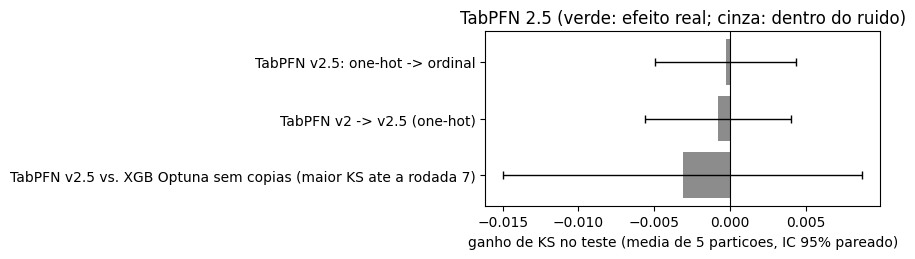

[ok] rodada7_tabpfn25


In [43]:
def rodada7_tabpfn25():
    if ja_versionada("fatores_rodada7b_tabpfn25.csv"):
        return
    if not os.environ.get("TABPFN_TOKEN"):
        raise RuntimeError("TABPFN_TOKEN ausente: crie o segredo no Kaggle (chave em https://ux.priorlabs.ai)")
    # Diagnostico da licenca (mesmas chamadas que o tabpfn faz antes de baixar os pesos)
    from tabpfn import browser_auth
    from tabpfn.settings import settings as tabpfn_settings
    api = tabpfn_settings.tabpfn.auth_api_url
    token = os.environ["TABPFN_TOKEN"].strip()
    valido = browser_auth.verify_token(token, api)
    licenca = browser_auth._get_license_name("tabpfn_2_5")
    aceita = browser_auth.check_license_accepted(token, api, licenca) if valido else None
    print(f"TABPFN_TOKEN valido: {valido} | licenca '{licenca}' aceita: {aceita}")
    if valido is False:
        raise RuntimeError("TABPFN_TOKEN rejeitado: copie a API Key de https://ux.priorlabs.ai/account "
                           "(nao o token do Hugging Face) e atualize o segredo")
    if aceita is False:
        raise RuntimeError(f"Licenca '{licenca}' nao aceita: aceite em "
                           "https://ux.priorlabs.ai/accept-license?hf_repo_id=tabpfn_2_5 e rode de novo")
    partes = []
    def r7b(rodada, nome, seed, D, fn):
        out = modelo_5p(rodada, nome, seed, D, fn)
        if out:
            for c, yy, pr in (("validacao", D["y"][2], out[1]), ("teste", D["y"][3], out[2])):
                partes.append(pd.DataFrame({"seed": seed, "modelo": nome, "conjunto": c, "y": yy, "p": pr}))
    for seed in range(5):
        D, _ = montar_particao(seed)
        r7b("rodada6", "tabpfn_v2_8est_onehot", seed, D, cfg_tabpfn(D, seed, "sem_copias", "neural", 8))
        r7b("rodada6", "xgb_optuna_sem_copias", seed, D, cfg(D, seed, hp_optuna("xgb"), *ALGORITMOS["xgb"][1:], "sem_copias"))
        r7b("rodada7", "tabpfn_v25_8est_onehot", seed, D, cfg_tabpfn_versao(D, seed, "v2.5", "neural"))
        r7b("rodada7", "tabpfn_v25_8est_ordinal", seed, D, cfg_tabpfn_versao(D, seed, "v2.5", "arvores"))
    pred = pd.concat(partes, ignore_index=True)
    if "tabpfn_v25_8est_onehot" not in set(pred["modelo"]):
        raise RuntimeError("TabPFN 2.5 falhou em todas as particoes (ver FALHAS); nada salvo")
    pred.to_csv(TABLES_DIR / "predicoes_5particoes_rodada7b.csv", index=False, float_format="%.6g")
    pd.DataFrame([l for l in INDICE_5P if l["modelo"].startswith("tabpfn_v25")]).to_csv(
        TABLES_DIR / "modelos_5_particoes_indice_rodada7b.csv", index=False)
    m = metricas_r5(pred)
    m.to_csv(TABLES_DIR / "rodada7b_metricas_por_particao.csv", index=False)
    resumo = m.groupby("modelo")[["ks", "auroc", "acuracia_limiar_05", "acuracia_limiar_validacao"]].agg(["mean", "std"])
    resumo.columns = [f"{a}_{b}" for a, b in resumo.columns]
    resumo = resumo.sort_values("ks_mean", ascending=False).reset_index()
    resumo.to_csv(TABLES_DIR / "rodada7b_resumo.csv", index=False)
    display(resumo.round(4))
    pares = [
        ("TabPFN v2 -> v2.5 (one-hot)", "ks", "tabpfn_v2_8est_onehot", "tabpfn_v25_8est_onehot"),
        ("TabPFN v2.5: one-hot -> ordinal", "ks", "tabpfn_v25_8est_onehot", "tabpfn_v25_8est_ordinal"),
        ("TabPFN v2.5 vs. XGB Optuna sem copias (maior KS ate a rodada 7)", "ks",
         "xgb_optuna_sem_copias", "tabpfn_v25_8est_onehot"),
        ("TabPFN v2 -> v2.5 (one-hot), acuracia no limiar da validacao", "acuracia_limiar_validacao",
         "tabpfn_v2_8est_onehot", "tabpfn_v25_8est_onehot"),
    ]
    linhas = []
    for fator, metrica, a, b in pares:
        try:
            linhas.append({"fator": fator, "config_a": a, "config_b": b, **pareado(m, a, b, metrica)})
        except KeyError as e:
            print(f"sem dados para '{fator}': {e}")
    fatores = pd.DataFrame(linhas)
    fatores.to_csv(TABLES_DIR / "fatores_rodada7b_tabpfn25.csv", index=False)
    display(fatores.round(4))
    grafico_fatores(fatores[fatores["metrica"] == "ks"], "fatores_rodada7b_tabpfn25.png",
                    "TabPFN 2.5 (verde: efeito real; cinza: dentro do ruido)")

rodar("rodada7_tabpfn25", rodada7_tabpfn25)


In [44]:
if (TABELAS_REPO / "fatores_rodada7b_tabpfn25.csv").exists():
    print("[pulado] salvamento da rodada 7b (ja versionada)")
elif not (TABLES_DIR / "fatores_rodada7b_tabpfn25.csv").exists():
    print("[pulado] salvamento da rodada 7b: TabPFN 2.5 nao rodou (ver FALHAS)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "rodada7b_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")
    salvar_saida("results/churn-tabpfn25", "results_churn_tabpfn25", "results: TabPFN 2.5 em 5 particoes (Kaggle)")


Falhas: nenhuma
Zip gerado: /kaggle/working/results_churn_tabpfn25.zip
  ja versionado, mantido como esta: reports/tables/modelos_5_particoes_indice.csv
Resultados enviados para a branch results/churn-tabpfn25.
